# EMOVID：从原始 BDF 到 3 秒 EEG 窗口与质量复核

以 **20261022161317_20261022_lwh / lwh.bdf** 为例，依次回答：读到了什么、
标签如何落到 EEG 时间轴、每一步如何改变信号、哪些窗口不通过、结果是否与生产流程一致。

在 VS Code/Jupyter 选择 **Python (EEGPT)** 内核，从上到下运行。
本文件保存了实际执行的图表；更换数据时修改下一格的 `RAW_URI` 并重新运行全部单元。
需要该 BDF 已通过统一入口生成同名 Lance 与 sidecar，以及本机已配置的 `rustfs` profile。

流程：**BDF 数字值 → 标定为 μV → 事件/日志对齐 → 标签内窗口索引 → 带上下文滤波
→ 200 Hz → 3 秒切窗 → 裁剪前质控 → 除以 200 并裁剪 → 对照 Lance**。

- 使用现有 `SignalReader`、`ClockAlignment`、`process_recording`、`window_plan`、
  `filter_and_resample`、`encode_window`，不是另一套预处理标准。
- 默认重算这一份 BDF 的**全部可用标签窗口**，不是只展示一段好看的波形；没有标签的时间不算作休息。
- 直接以 S3 Range 读取波形，按块释放内存，不下载整份 BDF，也不写入/覆盖生产数据。
  只在 Notebook 中保留小型表格和图像；注释读取函数会自动清理 `/tmp` 临时文件。
- 图题用英文避免缺失中文字体；解释和代码注释使用中文。静态图无需 widgets，最后可选交互浏览。

In [4]:
from pathlib import Path
import sys, math, hashlib, gc
from collections import Counter
from fractions import Fraction
from zoneinfo import ZoneInfo
from datetime import datetime

# 从仓库根目录或 notebooks/ 启动都可以。
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'preprocessing' / 'common' / 'emovid_pipeline.py').is_file()), None)
if PROJECT is None:
    raise RuntimeError('请在 personalized_FM 或其 notebooks 子目录启动内核')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import scipy, mne, lance
from IPython.display import display, Markdown
from preprocessing.common.emovid_segments import (Store, split_s3, recording_header, load_annotations,
                             normalize_events, ClockAlignment, EVENT_CODES, event_time)
from preprocessing.common.batch_emovid_segments import (list_objects, discover_recordings, process_recording,
                                   raw_run_intervals, header_datetime, log_wall_origin)
from preprocessing.common.emovid_storage import OutputStore, recording_path
from preprocessing.common.emovid_pipeline import mapping_signature
from preprocessing.common import preprocess_emovid_rules as prep

%matplotlib inline
plt.rcParams.update({'figure.figsize': (13, 4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})
pd.set_option('display.max_colwidth', 90)

RAW_URI = ('s3://oi-data@us-east-1/EMOVID_RAW/20261022161317_20261022_lwh/'
           '20261022161317_20261022_lwh/lwh/lwh.bdf')
PROFILE = 'rustfs'
OUTPUT_URI = 's3://personalized-fm/processed'
LABEL_ROOT = 's3://oi-data/EMOVID-261029'
TIMEZONE = 'Asia/Shanghai'    # 与现有映射一致；BDF 文件头本身不存时区
DEMO_WINDOW_INDEX = None    # None：第一个情绪窗口；也可填后面窗口表的整数索引
PREVIEW_CHANNELS = ['FP1', 'FZ', 'CZ', 'PZ', 'O1', 'O2']
ENABLE_WIDGETS = False     # 最后一节可选；默认图表无需 widget 支持

bucket, key = split_s3(RAW_URI)
RAW_URI = f's3://{bucket}/{key}'
NAME = str(recording_path(RAW_URI))
store = Store(PROFILE)
output = OutputStore(store.s3, OUTPUT_URI)   # 凭据只在内存中使用，不打印这个对象或 options
saved = output.read_json(NAME + '.summary.json')
saved_mapping = output.read_json(NAME + '.segments.json')
config = saved['config']
assert split_s3(saved['raw_uri']) == split_s3(RAW_URI)
assert config['window_seconds'] == 3 and config['target_sfreq'] == 200
assert config['source_unit_declaration'] == 'uV' and config['source_unit_status'] == 'confirmed'
assert config['channel_names'] == list(prep.CHANNELS)
assert config['bandpass_hz'] == [.3, 75.] and config['notch_hz'] == 50.
assert config['notch_width_hz'] == .25 and config['notch_transition_hz'] == 1.
assert config['resampling'] == 'scipy_resample_poly'
assert config['filter'] == 'MNE_zero_phase_FIR_firwin_hamming_reflect_limited'
assert config['normalization'] == 'clip(x_uV / 200, -1, 1)'
assert config['reference'] == 'acquisition_reference_unchanged'
assert not any(config[k] for k in ['car_applied', 'baseline_correction_applied', 'ica_applied', 'mvnn_applied'])
dataset = lance.dataset(output.uri(NAME + '.lance'), version=saved['lance_version'],
                        storage_options=output.options)
versions = pd.DataFrame({'运行环境': [mne.__version__, np.__version__, scipy.__version__],
                         '已有数据': [config['mne_version'], config['numpy_version'], config['scipy_version']]},
                        index=['MNE', 'NumPy', 'SciPy'])
display(versions)
print('示例：', NAME, '\nLance：', output.uri(NAME + '.lance'))
print('读取固定版本：', dataset.version, '；已有窗口数：', dataset.count_rows())

,运行环境,已有数据
MNE,1.4.2,1.4.2
NumPy,1.26.4,1.26.4
SciPy,1.10.1,1.10.1


示例： 20261022161317_20261022_lwh 
Lance： s3://personalized-fm/processed/20261022161317_20261022_lwh.lance
读取固定版本： 1 ；已有窗口数： 273


## 1. 文件头、通道与单位：这里还没有滤波

`SignalReader` 读取 BDF 的有符号 24 位整数，并逐通道使用文件头的 physical/digital min/max：

`physical = digital × (physical_max − physical_min)/(digital_max − digital_min) + offset`。

本批数据非标准单位 `uV/mm` 已由用户确认按 **μV** 处理，因此显式传入 `source_unit='uV'`。
选取并排序 59 个头皮通道，去掉 ECG/EOG/注释；保持采集参考，不做 CAR。
图中的标准电极位置只用于定位通道，不是受试者实测坐标。

,读取结果
BDF 起点（按 Asia/Shanghai 解释）,2026-10-22 16:13:19+08:00
采集目录时间（仅搜索线索）,20261022161317
时长 / 秒,5181.0
源采样率 / Hz,1000.0
文件大小 / MiB,950.17
选中通道数,59
文件头单位,[uV/mm]
按 μV 解释的依据,explicit_user_confirmation
移除的通道,"[ECG, HEOR, HEOL, VEOU, VEOL, BDF Annotations]"


,channel,source_index,header_unit,digital_to_physical_scale,physical_offset,physical_to_uV
0,FPZ,0,uV/mm,0.044703,0.022352,1.0
1,FP1,1,uV/mm,0.044703,0.022352,1.0
2,FP2,2,uV/mm,0.044703,0.022352,1.0
3,AF3,3,uV/mm,0.044703,0.022352,1.0
4,AF4,4,uV/mm,0.044703,0.022352,1.0
5,AF7,5,uV/mm,0.044703,0.022352,1.0
6,AF8,6,uV/mm,0.044703,0.022352,1.0
7,FZ,7,uV/mm,0.044703,0.022352,1.0
8,F1,8,uV/mm,0.044703,0.022352,1.0
9,F2,9,uV/mm,0.044703,0.022352,1.0


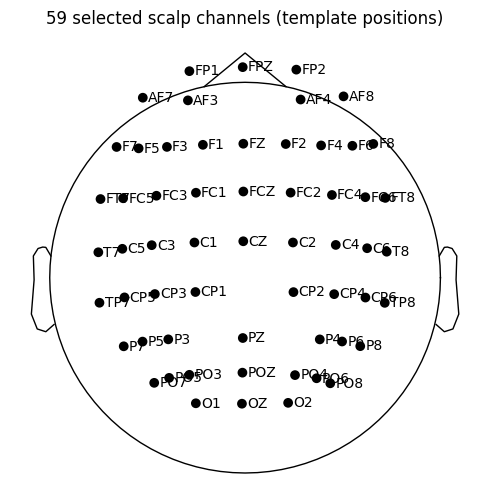

In [5]:
reader = prep.SignalReader(store, RAW_URI, source_unit='uV')
header = recording_header(store, RAW_URI)
head = store.s3.head_object(Bucket=bucket, Key=key)
assert head['ContentLength'] == reader.expected_size
assert reader.sfreq == header['sfreq']
START_WALL = pd.Timestamp(header_datetime(header), tz=TIMEZONE)
TARGET = float(config['target_sfreq'])

def wall_time(seconds):
    return START_WALL + pd.to_timedelta(seconds, unit='s')

display(pd.Series({'BDF 起点（按 Asia/Shanghai 解释）': str(START_WALL),
                   '采集目录时间（仅搜索线索）': NAME.split('_')[0],
                   '时长 / 秒': reader.duration, '源采样率 / Hz': reader.sfreq,
                   '文件大小 / MiB': round(head['ContentLength']/2**20, 2),
                   '选中通道数': len(reader.channel_names),
                   '文件头单位': sorted(set(reader.units)),
                   '按 μV 解释的依据': saved.get('unit_confirmation', {}).get('basis', 'confirmed'),
                   '移除的通道': reader.dropped_channels}, name='读取结果').to_frame())
channel_table = pd.DataFrame({
    'channel': reader.channel_names, 'source_index': reader.picks, 'header_unit': reader.units,
    'digital_to_physical_scale': [p[0] for p in reader.parameters],
    'physical_offset': [p[1] for p in reader.parameters],
    'physical_to_uV': [p[2] for p in reader.parameters]})
display(channel_table.head(10))
montage = mne.channels.make_standard_montage('standard_1020')
sensor_info = mne.create_info(list(reader.channel_names), TARGET, 'eeg')
sensor_info.set_montage(montage, match_case=False, on_missing='raise')
fig, ax = plt.subplots(figsize=(7, 6))
mne.viz.plot_sensors(sensor_info, axes=ax, show_names=True, show=False)
ax.set_title('59 selected scalp channels (template positions)')
plt.show()

## 2. 重新搜索标签与对齐，而不是只读已有标签

目录时间用于筛选候选日志；最终还要匹配 `101/102` 采集 run、共享触发码序列及真实时钟。
允许的默认条件：共享触发覆盖率 ≥80%、时钟斜率 0.98–1.02、最大拟合残差 ≤0.5 秒、
日志与设备墙钟差 ≤30 秒。情绪 `150/151` 使用实际设备时间；长休息只有本地日志时，
在相邻已匹配触发之间插值，禁止外推。**不是把文件名时间直接当作所有标签的时间零点。**

以下重新运行现有映射函数，并与已保存的分段签名对照。若源日志或映射逻辑变化，断言会停止，
避免用新边界解释旧波形。评分、等待、未匹配区间都不会自动变成 rest。

| 编码 | 含义 | 本次记录 |
|---|---|---|
| `101 / 102` | 采集会话开始／结束 | 3 对 |
| `130 / 131` | 注视十字开始／结束 | 139 对 |
| `132 / 133` | 普通视频开始／结束 | 101 对 |
| `150 / 151` | 情绪视频开始／结束 | 38 对 |
| `140 / 141` | 试次开始／结束 | 139 次开始、137 次结束 |
| `156 / 157` | 试次后的短休息开始／结束 | 136 对 |
| `158 / 159` | 喜好问题呈现／响应 | 101 次呈现、99 次响应 |
| `160 / 161` | 内容抽查题呈现／响应 | 4 对 |
| `162 / 163` | 疲劳问题呈现／响应 | 4 对 |
| `110–115` | 静息基线及睁眼／闭眼基线标记 | 未出现 |
| `152–155` | 效价与唤醒评分呈现／响应 | 未出现 |

In [21]:
source_objects = list_objects(store, RAW_URI.rsplit('/', 1)[0])
recordings, ignored = discover_recordings(source_objects)
recording = next(r for r in recordings if r['raw_uri'] == RAW_URI or RAW_URI in r['aliases'])
assert recording['raw_uri'] == RAW_URI, '请将 RAW_URI 改为去重后的 canonical raw_uri'
logs = [o for o in list_objects(store, LABEL_ROOT)
        if Path(o['uri']).name.startswith('events') and o['uri'].endswith('.json')]
mapping_config = dict(min_segment_seconds=3., output_sfreq=200., search_padding_seconds=600.,
                      timezone=TIMEZONE, wall_tolerance_seconds=30., max_residual_seconds=.5)
report = process_recording(recording, logs, store, mapping_config)
assert report['segments'], f"没有可用映射：{report['status']}"
assert mapping_signature(report) == saved['mapping_signature'] == mapping_signature(saved_mapping)
segments = pd.DataFrame(report['segments'])
segments['label_name'] = segments.emotion_label.where(segments.segment_type.eq('emotion'), 'rest')
segments['wall_start'] = wall_time(segments.start_seconds)
segments['wall_stop'] = wall_time(segments.stop_seconds)
display(pd.DataFrame([dict(run=m['raw_run_index'], events_uri=m['events_uri'],
                          **m['alignment'], wall_difference_s=m['wall_clock_difference_seconds'])
                      for m in report['matches']]))
display(segments[['label_name', 'rest_type', 'start_seconds', 'stop_seconds',
                  'wall_start', 'duration_seconds', 'usable', 'exclusion_reasons']].head(12))
print('映射状态：', report['status'], '；候选日志：', report['candidate_count'],
      '；匹配日志：', len(report['matches']), '；未匹配 run：', len(report['unmatched_runs']))
if report['rejected_candidates']:
    display(pd.DataFrame(report['rejected_candidates']))
issues = [dict(run=m['raw_run_index'], **issue) for m in report['matches']
          for issue in m['pairing_issues']]
if issues:
    display(pd.DataFrame(issues))

,run,events_uri,method,source_clock,matched_triggers,log_triggers,raw_triggers_with_log_codes,log_coverage,clock_slope,clock_intercept_seconds,maximum_fit_residual_seconds,median_fit_residual_seconds,wall_difference_s
0,0,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_162320/events.json,common_trigger_sequence_and_piecewise_linear_interpolation,flip_callback_time_monotonic_sec,18,18,18,1.0,1.000084,-536469.310788,0.000519,0.000153,0.037494
1,1,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_162754/events.json,common_trigger_sequence_and_piecewise_linear_interpolation,flip_callback_time_monotonic_sec,150,150,150,1.0,1.000085,-536469.820436,0.000714,0.000235,0.018246
2,2,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_163806/events.json,common_trigger_sequence_and_piecewise_linear_interpolation,flip_callback_time_monotonic_sec,1158,1158,1158,1.0,1.000085,-536469.989251,0.002035,0.000262,0.174338


,label_name,rest_type,start_seconds,stop_seconds,wall_start,duration_seconds,usable,exclusion_reasons
0,rest,short_rest,629.370,631.388,2026-10-22 16:23:48.370000+08:00,2.018,False,[below_minimum_duration]
1,rest,short_rest,897.393,899.403,2026-10-22 16:28:16.393000+08:00,2.010,False,[below_minimum_duration]
2,positive,None,903.976,916.924,2026-10-22 16:28:22.976000+08:00,12.948,True,[]
3,rest,short_rest,918.919,920.200,2026-10-22 16:28:37.919000+08:00,1.281,False,[below_minimum_duration]
4,rest,short_rest,942.241,943.231,2026-10-22 16:29:01.241000+08:00,0.990,False,[below_minimum_duration]
5,rest,short_rest,967.092,968.344,2026-10-22 16:29:26.092000+08:00,1.252,False,[below_minimum_duration]
6,rest,short_rest,1009.917,1010.953,2026-10-22 16:30:08.917000+08:00,1.036,False,[below_minimum_duration]
7,neutral,None,1015.635,1028.326,2026-10-22 16:30:14.635000+08:00,12.691,True,[]
8,rest,short_rest,1029.990,1031.994,2026-10-22 16:30:28.990000+08:00,2.004,False,[below_minimum_duration]
9,rest,short_rest,1064.834,1066.847,2026-10-22 16:31:03.834000+08:00,2.013,False,[below_minimum_duration]


映射状态： success ；候选日志： 5 ；匹配日志： 3 ；未匹配 run： 0


,events_uri,reason
0,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_160505/events.json,no_device_session_start_near_log_start
1,s3://oi-data/EMOVID-261029/13467638/session_10/20261022_160751/events.json,no_device_session_start_near_log_start


,bdf_seconds,code,event,source_sample,output_sample,grid_error_ms,wall_time
0,101.279,250,unknown,101279,20256,1.0,2026-10-22 16:15:00.279000+08:00
1,101.667,251,unknown,101667,20333,-2.0,2026-10-22 16:15:00.667000+08:00
2,102.042,252,unknown,102042,20408,-2.0,2026-10-22 16:15:01.042000+08:00
3,391.980,250,unknown,391980,78396,0.0,2026-10-22 16:19:50.980000+08:00
4,392.336,251,unknown,392336,78467,-1.0,2026-10-22 16:19:51.336000+08:00
5,392.777,252,unknown,392777,78555,-2.0,2026-10-22 16:19:51.777000+08:00
6,597.508,250,unknown,597508,119502,2.0,2026-10-22 16:23:16.508000+08:00
7,598.083,251,unknown,598083,119617,2.0,2026-10-22 16:23:17.083000+08:00
8,598.462,252,unknown,598462,119692,-2.0,2026-10-22 16:23:17.462000+08:00
9,606.780,101,session_start,606780,121356,0.0,2026-10-22 16:23:25.780000+08:00


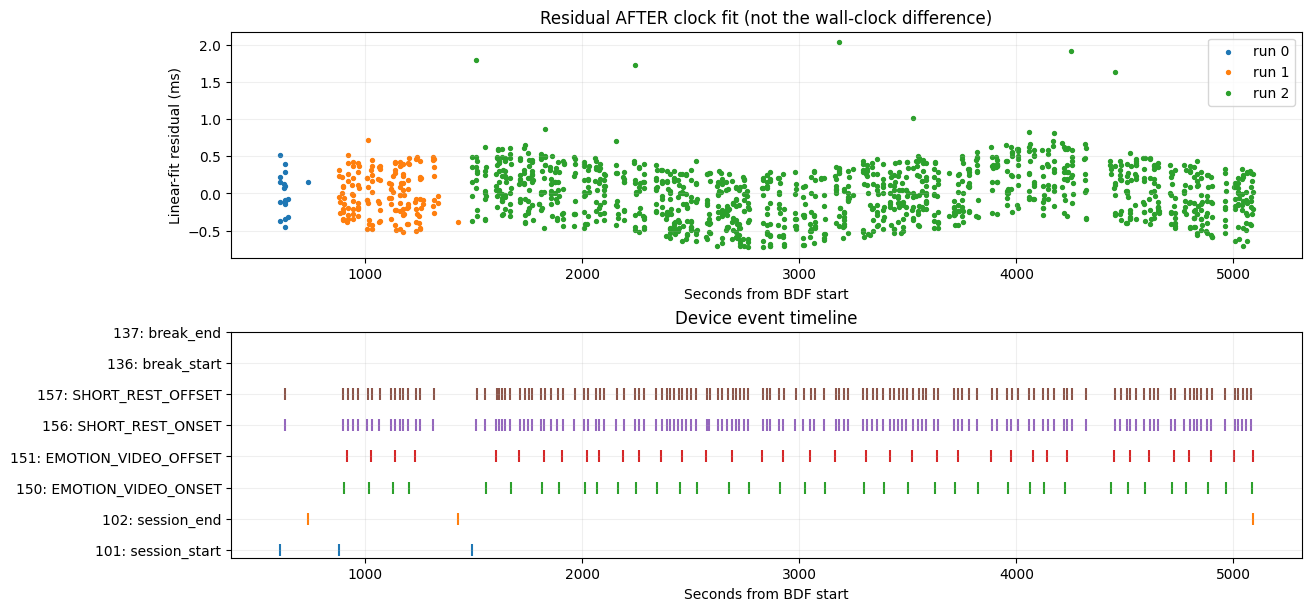

拟合后的最大残差（不是墙钟差，毫秒）： 2.035
200 Hz 网格最大量化误差（毫秒）： 2.0


In [22]:
raw_events, annotation_uri = load_annotations(store, RAW_URI, report['annotations_uri'])
event_names = {v: k for k, v in EVENT_CODES.items()}
events_df = pd.DataFrame(raw_events, columns=['bdf_seconds', 'code'])
events_df['event'] = events_df.code.map(event_names).fillna('unknown')
events_df['source_sample'] = np.rint(events_df.bdf_seconds * reader.sfreq).astype('int64')
events_df['output_sample'] = np.rint(events_df.bdf_seconds * TARGET).astype('int64')
events_df['grid_error_ms'] = (events_df.output_sample/TARGET-events_df.bdf_seconds)*1000
events_df['wall_time'] = wall_time(events_df.bdf_seconds)
display(events_df.head(12))

runs = raw_run_intervals(raw_events, reader.duration)
anchor_rows = []
for match in report['matches']:
    run = match['raw_run_index']
    a, b = runs[run]
    log = normalize_events(store.json(match['events_uri']))
    alignment = ClockAlignment(log, [(t, c) for t, c in raw_events if a <= t <= b])
    for event_index, t in alignment.exact.items():
        source_t = alignment.source_time(log[event_index])
        fit_t = (alignment.report['clock_intercept_seconds'] +
                 alignment.report['clock_slope']*source_t)
        anchor_rows.append(dict(run=run, bdf_seconds=t, event=log[event_index]['name'],
                                residual_ms=1000*(t-fit_t)))
anchors = pd.DataFrame(anchor_rows)
fig, axes = plt.subplots(2, 1, figsize=(13, 6), layout='constrained')
for run, group in anchors.groupby('run'):
    axes[0].scatter(group.bdf_seconds, group.residual_ms, s=8, label=f'run {run}')
axes[0].set(xlabel='Seconds from BDF start', ylabel='Linear-fit residual (ms)',
            title='Residual AFTER clock fit (not the wall-clock difference)')
axes[0].legend()
codes = [101, 102, 150, 151, 156, 157, 136, 137]
for i, c in enumerate(codes):
    ts = events_df.loc[events_df.code.eq(c), 'bdf_seconds']
    axes[1].scatter(ts, np.full(len(ts), i), marker='|', s=80)
axes[1].set(yticks=range(len(codes)), yticklabels=[f'{c}: {event_names[c]}' for c in codes],
            xlabel='Seconds from BDF start', title='Device event timeline')
plt.show()
print('拟合后的最大残差（不是墙钟差，毫秒）：', round(anchors.residual_ms.abs().max(), 4))
print('200 Hz 网格最大量化误差（毫秒）：', round(events_df.grid_error_ms.abs().max(), 4))

## 2.1 日志与设备墙钟差：同一个触发事件的两种绝对时间

前面匹配表的 **`wall_difference_s`** 来自分段报告
`matches[*].wall_clock_difference_seconds`；前面的残差曲线则来自 `alignment`，不是这项指标。
这里将墙钟差独立展开。所有绝对时间统一按 **Asia/Shanghai** 展示。

对已经通过触发码序列配对的同一事件 $i$：

$$T_{device,i}=T_{BDF\ header}+t_{BDF\ event,i}$$
$$T_{log,i}=T_{log\ origin}+t_{relative,i},\qquad
\Delta_i=T_{device,i}-T_{log,i}$$

生产代码先用日志中**第一个含 `payload.timestamp_unix_sec` 的事件**求
`log_origin = Unix绝对时间 − relative_time_sec`，再重建其他事件的日志墙钟；
找不到该字段才退回日志目录时间。下面直接调用相同的 `log_wall_origin`，并展示这一起点的来源。
因此 `log_wall_time` 是生产规则重建的时间，**并不是每一行直接使用自身的 Unix 字段**。
`payload_wall_time` 另列出该事件自身的原始 Unix 时间（缺失为 NaT），用于追溯，不参与本项判定。

| 指标 | 算法与作用 |
|---|---|
| 有符号墙钟差 | `设备墙钟 − 日志墙钟`；正值表示设备所标时间更晚，负值表示更早 |
| 生产记录的墙钟差 | 每个 run 的 **`median(abs(Δ))`**；不是 `abs(median(Δ))`，也不是最大值 |
| 墙钟匹配门限 | 先要求日志首事件与设备 run 起点接近（≤30 秒），再要求上述中位绝对差 ≤30 秒 |
| 时钟拟合残差 | 将日志单调时钟做线性拟合后，设备秒数与拟合秒数之差；检查触发序列的一致性 |

**30 秒是排除错误日志候选的宽松门限，不是最终情绪边界允许错开 30 秒。**
情绪边界仍使用 BDF 实际触发；本地休息事件在共享触发之间插值。
墙钟差可能混合文件头起点的秒级精度、两端时钟偏移/漂移及事件记录延迟，不能直接解释为纯硬件传输延迟。

In [9]:
# 重新使用生产时钟配对，显式保留两个时间源以及 signed delta。
wall_rows, origin_rows, wall_run_rows = [], [], []
for match in report['matches']:
    run = match['raw_run_index']
    run_start, run_stop = runs[run]
    log = normalize_events(store.json(match['events_uri']))
    alignment = ClockAlignment(log, [(t, c) for t, c in raw_events if run_start <= t <= run_stop],
                               max_residual_seconds=mapping_config['max_residual_seconds'])
    origin, basis = log_wall_origin(log, match['events_uri'], TIMEZONE)
    assert basis == match['wall_clock_basis']
    origin_wall = pd.Timestamp(origin, tz=TIMEZONE)
    origin_from_bdf_s = (origin-header_datetime(header)).total_seconds()
    origin_event = next((i for i, e in enumerate(log)
                         if isinstance(e.get('payload', {}).get('timestamp_unix_sec'), (int, float))), None)
    origin_rows.append(dict(run=run, events_uri=match['events_uri'], wall_clock_basis=basis,
                             origin_event_index=origin_event,
                             origin_event_name=log[origin_event]['name'] if origin_event is not None else None,
                             log_origin_wall=origin_wall, bdf_header_wall=START_WALL))
    run_rows = []
    for event_index, device_s in alignment.exact.items():
        event = log[event_index]
        log_s = origin_from_bdf_s + event_time(event)
        # 在相对秒轴上相减，完全复用生产算法，避免大 Unix 秒数相减的精度损失。
        delta_s = device_s-log_s
        payload_unix = event.get('payload', {}).get('timestamp_unix_sec')
        payload_wall = (pd.Timestamp(payload_unix, unit='s', tz='UTC').tz_convert(TIMEZONE)
                        if isinstance(payload_unix, (int, float)) and np.isfinite(payload_unix)
                        else pd.NaT)
        fit_s = (alignment.report['clock_intercept_seconds'] +
                  alignment.report['clock_slope']*alignment.source_time(event))
        run_rows.append(dict(run=run, event_index=event_index, event=event['name'],
                              bdf_seconds=device_s, relative_time_sec=event_time(event),
                              device_wall_time=wall_time(device_s), log_wall_time=wall_time(log_s),
                              payload_wall_time=payload_wall,
                              wall_delta_ms=delta_s*1000, fit_residual_ms=(device_s-fit_s)*1000))
    run_frame = pd.DataFrame(run_rows)
    delta = run_frame.wall_delta_ms.to_numpy()/1000
    median_absolute = float(np.median(np.abs(delta)))
    np.testing.assert_allclose(median_absolute, match['wall_clock_difference_seconds'], rtol=0, atol=1e-10)
    # 表中的绝对时间也必须复现同一差值（允许纳秒格式化舍入误差）。
    table_delta = (run_frame.device_wall_time-run_frame.log_wall_time).dt.total_seconds()
    np.testing.assert_allclose(table_delta, delta, rtol=0, atol=1e-8)
    run_start_delta_s = run_start - (origin_from_bdf_s + event_time(log[0]))
    wall_run_rows.append(dict(run=run, matched_events=len(run_rows),
                              median_signed_ms=float(np.median(delta)*1000),
                              median_absolute_ms=median_absolute*1000,
                              p95_absolute_ms=float(np.percentile(np.abs(delta), 95)*1000),
                              max_absolute_ms=float(np.abs(delta).max()*1000),
                              max_fit_residual_ms=float(run_frame.fit_residual_ms.abs().max()),
                              run_start_delta_ms=run_start_delta_s*1000,
                              gate_seconds=mapping_config['wall_tolerance_seconds'],
                              wall_gate_pass=(abs(run_start_delta_s) <= mapping_config['wall_tolerance_seconds']
                                               and median_absolute <= mapping_config['wall_tolerance_seconds'])))
    wall_rows.extend(run_rows)

wall_clock_events = pd.DataFrame(wall_rows)
wall_clock_runs = pd.DataFrame(wall_run_rows).set_index('run')
wall_clock_origins = pd.DataFrame(origin_rows).set_index('run')
assert len(wall_clock_events) == len(anchors)
assert wall_clock_runs.wall_gate_pass.all()

display(Markdown('**起点追溯：哪条日志、哪一个事件提供了日志绝对时间零点？**'))
display(wall_clock_origins)
display(Markdown('**各 run 汇总：毫秒。`median_absolute_ms` 就是生产字段乘以 1000。**'))
display(wall_clock_runs.round(4))

# 每个 run 展示首个、中间、最后一个共享触发，便于观察差值随时间的变化。
examples_wall = pd.concat([group.iloc[sorted({0, len(group)//2, len(group)-1})]
                           for _, group in wall_clock_events.groupby('run')])
time_example = examples_wall[['run', 'event_index', 'event', 'device_wall_time', 'log_wall_time',
                              'wall_delta_ms', 'fit_residual_ms']].copy()
for name in ['device_wall_time', 'log_wall_time']:
    time_example[name] = time_example[name].dt.strftime('%Y-%m-%d %H:%M:%S.%f %z')
display(Markdown('**同一事件的设备/日志绝对时间对照：正差值表示设备所标时间更晚。**'))
display(time_example.round(4).reset_index(drop=True))
print('完整逐事件表：wall_clock_events；按 run 汇总：wall_clock_runs；起点来源：wall_clock_origins')

**起点追溯：哪条日志、哪一个事件提供了日志绝对时间零点？**

,events_uri,wall_clock_basis,origin_event_index,origin_event_name,log_origin_wall,bdf_header_wall
run,,,,,,
0,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_162320/events.json,payload_timestamp_unix_sec,1,trial_start,2026-10-22 16:23:20.583494+08:00,2026-10-22 16:13:19+08:00
1,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_162754/events.json,payload_timestamp_unix_sec,1,trial_start,2026-10-22 16:27:54.713754+08:00,2026-10-22 16:13:19+08:00
2,s3://oi-data/EMOVID-261029/13467638/session_01/20261022_163806/events.json,payload_timestamp_unix_sec,1,trial_start,2026-10-22 16:38:06.033662+08:00,2026-10-22 16:13:19+08:00


**各 run 汇总：毫秒。`median_absolute_ms` 就是生产字段乘以 1000。**

,matched_events,median_signed_ms,median_absolute_ms,p95_absolute_ms,max_absolute_ms,max_fit_residual_ms,run_start_delta_ms,gate_seconds,wall_gate_pass
run,,,,,,,,,
0,18,-37.494,37.494,42.394,47.494,0.5190,-38.494,30.0,True
1,150,18.246,18.246,37.796,42.246,0.7138,-6.754,30.0,True
2,1158,174.338,174.338,324.338,345.338,2.0350,33.338,30.0,True


**同一事件的设备/日志绝对时间对照：正差值表示设备所标时间更晚。**

,run,event_index,event,device_wall_time,log_wall_time,wall_delta_ms,fit_residual_ms
0,0,0,session_start,2026-10-22 16:23:25.780000 +0800,2026-10-22 16:23:25.818494 +0800,-38.494,0.2170
1,0,9,SHORT_REST_ONSET,2026-10-22 16:23:48.370000 +0800,2026-10-22 16:23:48.411494 +0800,-41.494,0.3945
2,0,17,session_end,2026-10-22 16:25:37.701000 +0800,2026-10-22 16:25:37.724494 +0800,-23.494,0.1507
3,1,0,session_start,2026-10-22 16:27:59.863000 +0800,2026-10-22 16:27:59.869754 +0800,-6.754,-0.0543
4,1,75,SHORT_REST_ONSET,2026-10-22 16:31:59.197000 +0800,2026-10-22 16:31:59.182754 +0800,14.246,-0.0588
5,1,149,session_end,2026-10-22 16:37:05.489000 +0800,2026-10-22 16:37:05.447754 +0800,41.246,-0.3836
6,2,0,session_start,2026-10-22 16:38:11.239000 +0800,2026-10-22 16:38:11.205662 +0800,33.338,0.4878
7,2,579,fixation_off,2026-10-22 17:06:46.817000 +0800,2026-10-22 17:06:46.642662 +0800,174.338,-0.3585
8,2,1159,session_end,2026-10-22 17:38:08.945000 +0800,2026-10-22 17:38:08.611662 +0800,333.338,0.2559


完整逐事件表：wall_clock_events；按 run 汇总：wall_clock_runs；起点来源：wall_clock_origins


## 2.2 可视化墙钟差，并与拟合残差比较

第一幅图的**上图**是未拟合的墙钟差 Δ，下图是拟合后的残差；横轴都是 BDF 记录时间，
纵轴都是毫秒，但范围不同。各 run 分别绘制，不跨日志连接。差值随时间上升/下降可以提示
相对时钟漂移；只有这些时间戳无法区分时钟误差与所有记录延迟来源。

第二幅图左边显示各 run 的有符号差值分布；右边用**同一毫秒标尺**比较墙钟绝对差中位数与
最大拟合残差。右图蓝色条的数值是 `median(abs(Δ))`；左图箱体内的黑线才是有符号差值的中位数，灰色虚线表示零。
30 秒门限以文字列出，避免把几十到几百毫秒的实际差值压在一条接近零的线上。

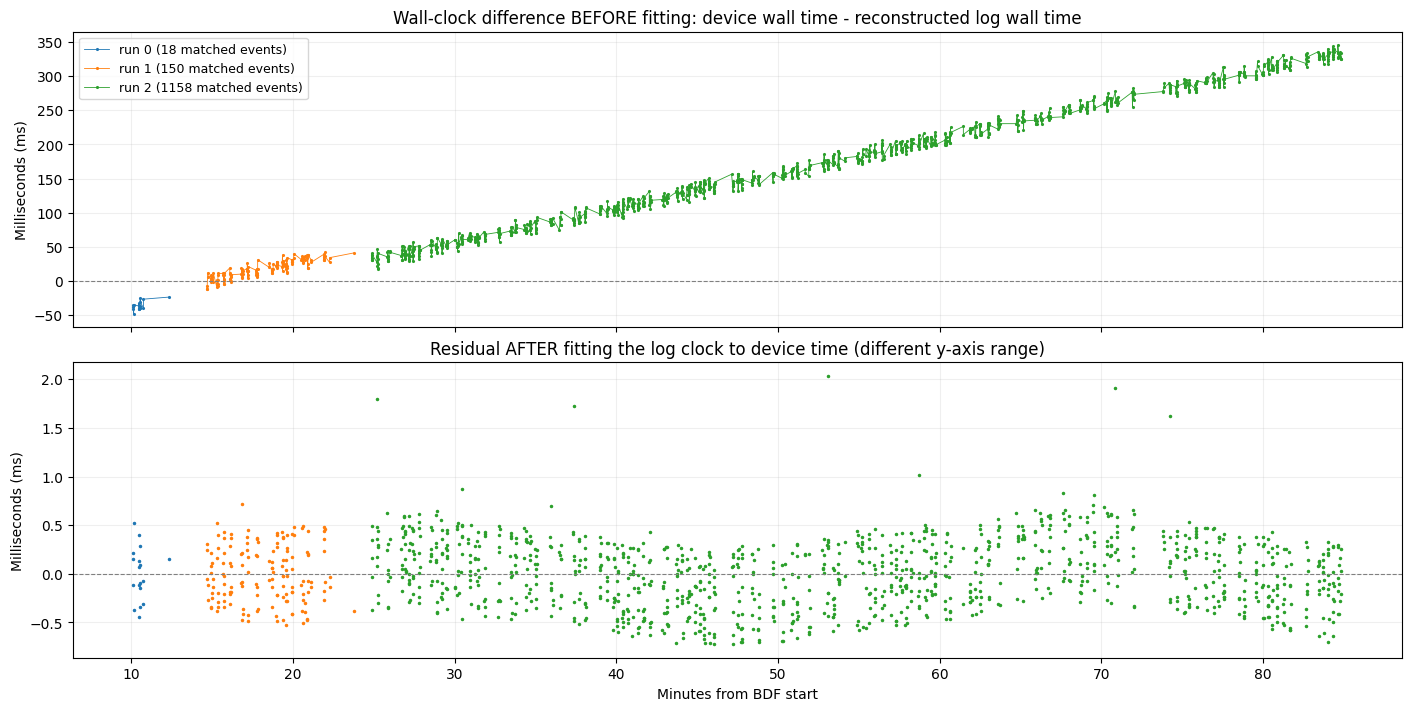

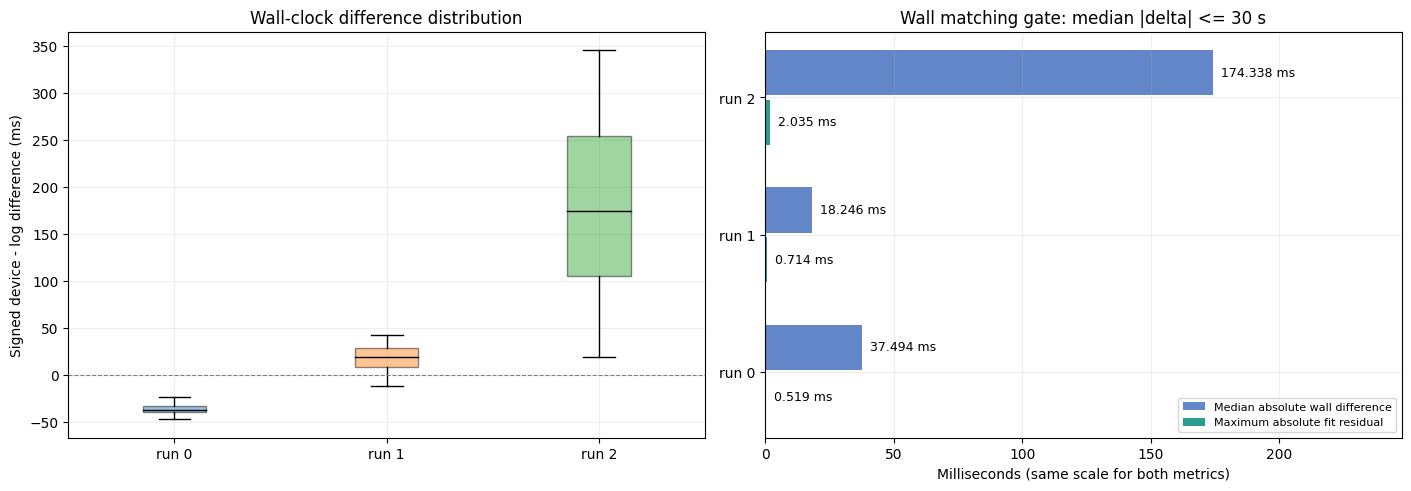

**run 0**：墙钟绝对差中位数 **37.494 ms**，有符号中位数 **-37.494 ms**，最大拟合残差 **0.519 ms**；墙钟匹配检查：**通过**。

**run 1**：墙钟绝对差中位数 **18.246 ms**，有符号中位数 **+18.246 ms**，最大拟合残差 **0.714 ms**；墙钟匹配检查：**通过**。

**run 2**：墙钟绝对差中位数 **174.338 ms**，有符号中位数 **+174.338 ms**，最大拟合残差 **2.035 ms**；墙钟匹配检查：**通过**。

In [10]:
run_colors = {int(run): plt.get_cmap('tab10')(i % 10) for i, run in enumerate(wall_clock_runs.index)}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout='constrained')
for run, group in wall_clock_events.groupby('run'):
    group = group.sort_values('bdf_seconds')
    color = run_colors[run]
    axes[0].plot(group.bdf_seconds/60, group.wall_delta_ms, '.-', ms=2.5, lw=.6,
                 color=color, label=f'run {run} ({len(group)} matched events)')
    axes[1].plot(group.bdf_seconds/60, group.fit_residual_ms, '.', ms=3, color=color)
for ax in axes:
    ax.axhline(0, color='gray', lw=.8, ls='--')
    ax.set_ylabel('Milliseconds (ms)')
axes[0].set_title('Wall-clock difference BEFORE fitting: device wall time - reconstructed log wall time')
axes[0].legend(loc='upper left', fontsize=9)
axes[1].set_title('Residual AFTER fitting the log clock to device time (different y-axis range)')
axes[1].set_xlabel('Minutes from BDF start')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout='constrained')
run_ids = wall_clock_runs.index.tolist()
bp = axes[0].boxplot([wall_clock_events.loc[wall_clock_events.run.eq(run), 'wall_delta_ms']
                      for run in run_ids], labels=[f'run {r}' for r in run_ids],
                     patch_artist=True, showfliers=True,
                     flierprops=dict(markersize=2), medianprops=dict(color='black'))
for patch, run in zip(bp['boxes'], run_ids):
    patch.set_facecolor(run_colors[run]); patch.set_alpha(.45)
axes[0].axhline(0, color='gray', ls='--', lw=.8)
axes[0].set(ylabel='Signed device - log difference (ms)', title='Wall-clock difference distribution')

y = np.arange(len(run_ids))
wall_values = wall_clock_runs.median_absolute_ms.to_numpy()
fit_values = wall_clock_runs.max_fit_residual_ms.to_numpy()
axes[1].barh(y+.18, wall_values, height=.33, color='#6386c8', label='Median absolute wall difference')
axes[1].barh(y-.18, fit_values, height=.33, color='#2a9d8f', label='Maximum absolute fit residual')
for pos, wall, fit in zip(y, wall_values, fit_values):
    axes[1].text(wall, pos+.18, f'  {wall:.3f} ms', va='center', fontsize=9)
    axes[1].text(fit, pos-.18, f'  {fit:.3f} ms', va='center', fontsize=9)
axes[1].set(yticks=y, yticklabels=[f'run {r}' for r in run_ids],
            xlabel='Milliseconds (same scale for both metrics)',
            xlim=(0, max(wall_values.max(), fit_values.max(), 1)*1.42),
            title=f"Wall matching gate: median |delta| <= {mapping_config['wall_tolerance_seconds']:g} s")
axes[1].legend(loc='lower right', fontsize=8)
plt.show()

for run, row in wall_clock_runs.iterrows():
    display(Markdown(f"**run {run}**：墙钟绝对差中位数 **{row.median_absolute_ms:.3f} ms**，"
                     f"有符号中位数 **{row.median_signed_ms:+.3f} ms**，"
                     f"最大拟合残差 **{row.max_fit_residual_ms:.3f} ms**；"
                     f"墙钟匹配检查：**{'通过' if row.wall_gate_pass else '不通过'}**。"))

## 3. 标签区间 → 不跨标签的 3 秒窗

下面用生产函数 `window_plan` 建索引：每个可用 emotion/rest 父片段独立切窗，
短于 3 秒的父片段排除，尾部不足 3 秒舍弃，相邻同标签视频也不合并，**完全不补零**。
所有索引从完整 BDF 起点计数，区间采用 `[start, stop)`。
先投影到 200 Hz 网格，端点四舍五入误差最多 2.5 ms；这与现有生产数据一致。
这里先建索引；实际信号先在含上下文的长块上滤波，再取这些窗口。

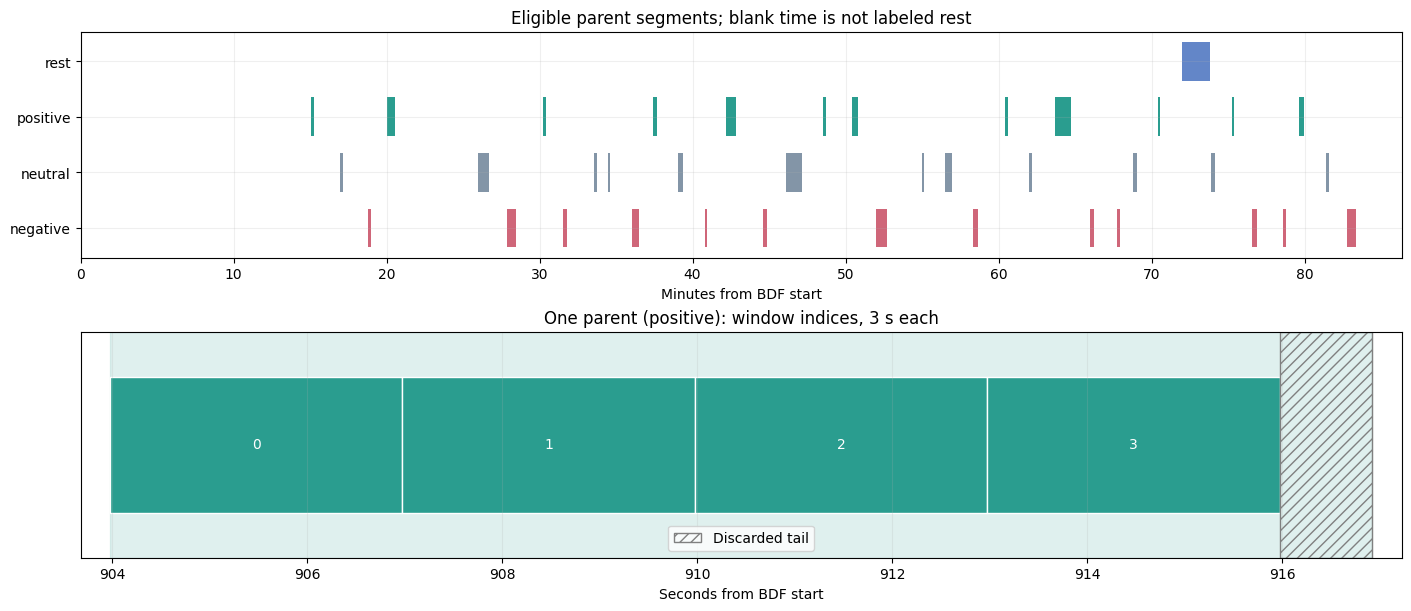

,segment_index,start,stop,window_index,start_time,stop_time,label_name,wall_start
0,2,180795,181395,0,903.975,906.975,positive,2026-10-22 16:28:22.975000+08:00
1,2,181395,181995,1,906.975,909.975,positive,2026-10-22 16:28:25.975000+08:00
2,2,181995,182595,2,909.975,912.975,positive,2026-10-22 16:28:28.975000+08:00
3,2,182595,183195,3,912.975,915.975,positive,2026-10-22 16:28:31.975000+08:00
4,7,203127,203727,0,1015.635,1018.635,neutral,2026-10-22 16:30:14.635000+08:00
5,7,203727,204327,1,1018.635,1021.635,neutral,2026-10-22 16:30:17.635000+08:00
6,7,204327,204927,2,1021.635,1024.635,neutral,2026-10-22 16:30:20.635000+08:00
7,7,204927,205527,3,1024.635,1027.635,neutral,2026-10-22 16:30:23.635000+08:00
8,11,225229,225829,0,1126.145,1129.145,negative,2026-10-22 16:32:05.145000+08:00
9,11,225829,226429,1,1129.145,1132.145,negative,2026-10-22 16:32:08.145000+08:00


,覆盖范围
完整录制 / 秒,5181.0
通过映射的父片段数,38
排除的父片段数,137
完整窗口数,273
完整窗口覆盖 / 秒,819
可用父片段尾部舍弃 / 秒,55.09
完整窗口占录制时长,15.8%


In [11]:
plan, tail_samples = prep.window_plan(report['segments'])
windows = pd.DataFrame(plan)
windows['start_time'] = windows.start/TARGET
windows['stop_time'] = windows.stop/TARGET
windows['label_name'] = [segments.loc[i, 'label_name'] for i in windows.segment_index]
windows['wall_start'] = wall_time(windows.start_time)
assert len(windows) == saved['n_windows'] == dataset.count_rows()
assert (windows.stop - windows.start).eq(600).all()
assert np.isclose(tail_samples/TARGET, saved['discarded_short_tail_seconds'])
for w in plan:
    parent = report['segments'][w['segment_index']]
    assert round(parent['start_seconds']*TARGET) <= w['start'] < w['stop'] <= round(parent['stop_seconds']*TARGET)
assert windows.start.is_unique and (windows.start.iloc[1:].to_numpy() >= windows.stop.iloc[:-1].to_numpy()).all()

COLORS = {'negative': '#cf6679', 'neutral': '#8395a7', 'positive': '#2a9d8f', 'rest': '#6386c8'}
fig, axes = plt.subplots(2, 1, figsize=(14, 6), layout='constrained')
for i, label in enumerate(COLORS):
    rows = segments[segments.usable & segments.label_name.eq(label)]
    axes[0].broken_barh([(r.start_seconds/60, r.duration_seconds/60) for r in rows.itertuples()],
                        (i-.35, .7), facecolors=COLORS[label])
axes[0].set(yticks=range(4), yticklabels=list(COLORS), xlim=(0, reader.duration/60),
            xlabel='Minutes from BDF start', title='Eligible parent segments; blank time is not labeled rest')
demo_index = (int(windows.index[windows.label_name.ne('rest')][0])
              if DEMO_WINDOW_INDEX is None else int(DEMO_WINDOW_INDEX))
if demo_index not in windows.index:
    raise ValueError('DEMO_WINDOW_INDEX 超出窗口索引范围')
demo = windows.loc[demo_index]
parent = segments.loc[int(demo.segment_index)]
children = windows[windows.segment_index.eq(demo.segment_index)]
axes[1].axvspan(parent.start_seconds, parent.stop_seconds, alpha=.15, color=COLORS[parent.label_name])
for w in children.itertuples():
    axes[1].broken_barh([(w.start_time, 3)], (.2, .6), facecolors=COLORS[w.label_name], edgecolors='white')
    axes[1].text(w.start_time+1.5, .5, str(w.Index), ha='center', va='center', color='white')
tail_start = children.stop_time.max()
if tail_start < parent.stop_seconds:
    axes[1].axvspan(tail_start, parent.stop_seconds, facecolor='none', hatch='///', edgecolor='gray', label='Discarded tail')
    axes[1].legend()
axes[1].set(xlim=(parent.start_seconds-.3, parent.stop_seconds+.3), ylim=(0, 1), yticks=[],
            xlabel='Seconds from BDF start', title=f'One parent ({parent.label_name}): window indices, 3 s each')
plt.show()
display(windows.head(10))
display(pd.Series({'完整录制 / 秒': reader.duration, '通过映射的父片段数': int(segments.usable.sum()),
                   '排除的父片段数': int((~segments.usable).sum()), '完整窗口数': len(windows),
                   '完整窗口覆盖 / 秒': len(windows)*3, '可用父片段尾部舍弃 / 秒': tail_samples/TARGET,
                   '完整窗口占录制时长': f'{len(windows)*3/reader.duration:.1%}'}, name='覆盖范围').to_frame())

## 4. 按生产分块读取原始 EEG，并标记事件与窗边界

生产流程按窗口起点所属的 120 秒组处理，每组从最早窗口到最晚窗口并加左右各 15 秒上下文。
起点还要对齐到重采样网格。下面显式展示同一计算，后续与 Lance 逐窗核对。
只读取当前块，不一次载入整份约 86 分钟的 BDF。

原始图保持 μV 标定，**没有去均值或显示滤波**；各通道有独立纵轴。
绿色区域标出示例 3 秒窗，竖虚线是设备标记。高 DC 偏移、尖峰和工频都可能出现在原始图中。

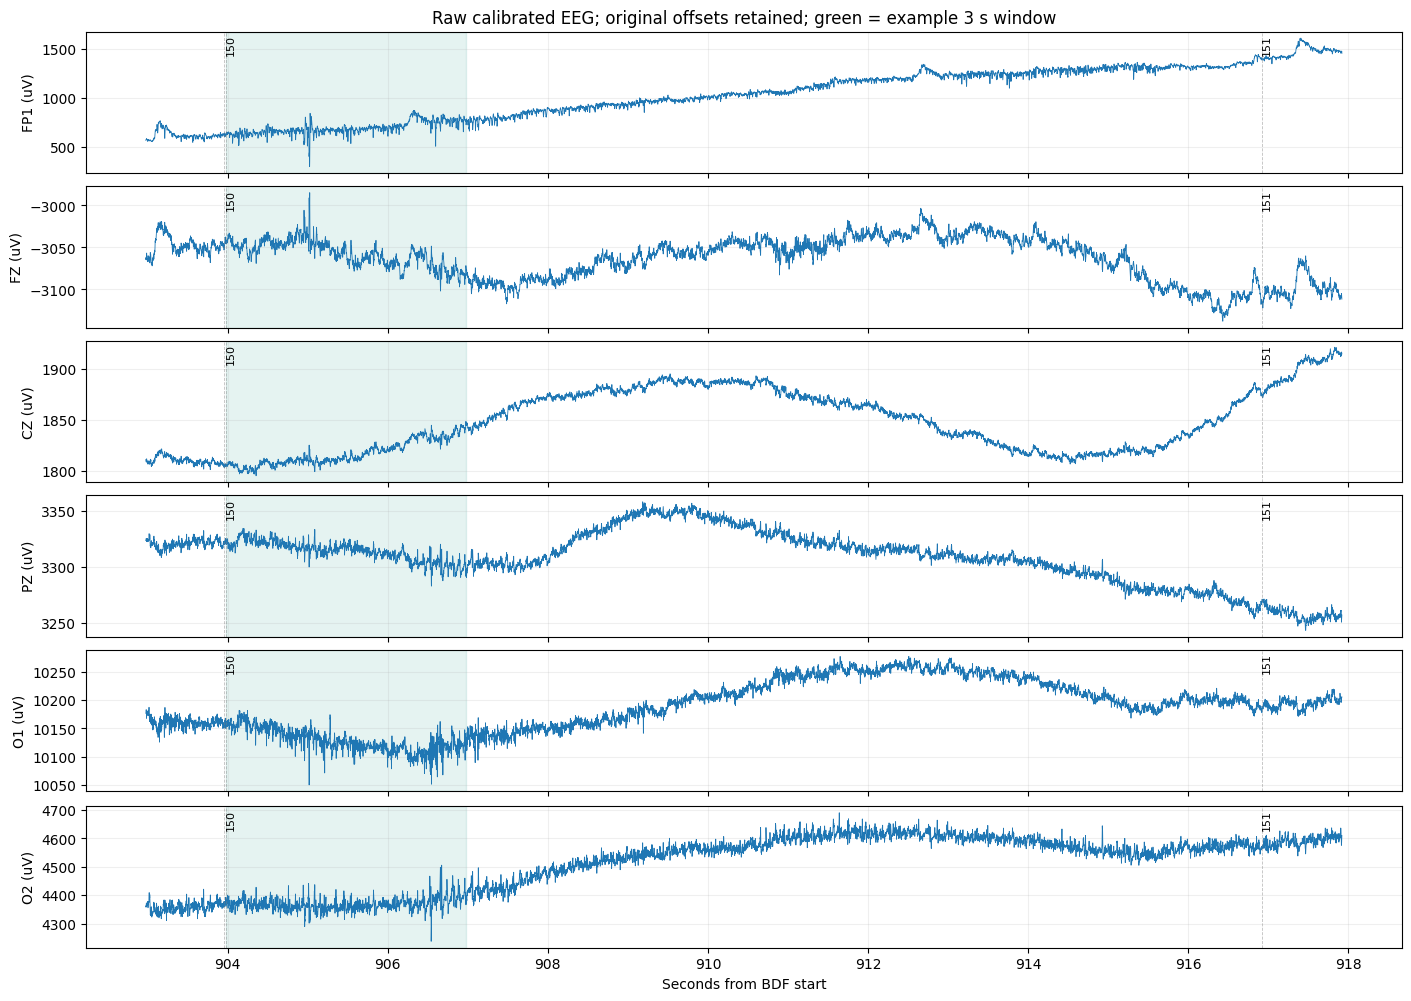

本块读取 (59, 42000)，float64 数组 18.9 MiB；全局范围 [888.975, 930.975) 秒
示例窗口绝对时间： 2026-10-22 16:28:22.975000+08:00 → 2026-10-22 16:28:25.975000+08:00


In [12]:
ratio = Fraction(TARGET/reader.sfreq).limit_denominator(10000)
groups = {}
for index, w in enumerate(plan):
    block_id = int(w['start']//round(config['block_seconds']*TARGET))
    groups.setdefault(block_id, []).append(index)

def block_bounds(indices):
    # 对应 preprocess_recording 的起点对齐和上下文计算。
    first = min(plan[i]['start'] for i in indices)/TARGET
    last = max(plan[i]['stop'] for i in indices)/TARGET
    start = max(0, math.floor((first-config['context_seconds'])*reader.sfreq))
    start = start//ratio.denominator*ratio.denominator
    stop = min(reader.n_times, math.ceil((last+config['context_seconds'])*reader.sfreq))
    return start, stop, round(start*TARGET/reader.sfreq)

demo_block = int(demo.start//round(config['block_seconds']*TARGET))
demo_indices = groups[demo_block]
raw_start, raw_stop, output_offset = block_bounds(demo_indices)
raw_uv = reader.read_samples(raw_start, raw_stop)
preview_start = max(raw_start/reader.sfreq, parent.start_seconds-1)
preview_stop = min(raw_stop/reader.sfreq, parent.stop_seconds+1, preview_start+25)

def mark_events(ax, left, right):
    subset = events_df[events_df.bdf_seconds.between(left, right)]
    for event in subset.itertuples():
        ax.axvline(event.bdf_seconds, color='gray', lw=.6, ls='--', alpha=.5)
    # 只给最关键的边界标码，避免文字遮住波形。
    for event in subset[subset.code.isin([101, 102, 150, 151, 156, 157])].itertuples():
        ax.text(event.bdf_seconds, .98, str(event.code), transform=ax.get_xaxis_transform(),
                rotation=90, va='top', fontsize=8)

selected_channels = [ch for ch in PREVIEW_CHANNELS if ch in prep.CHANNELS]
if not selected_channels:
    raise ValueError('PREVIEW_CHANNELS 中没有有效 EEG 通道')
raw_t = (raw_start+np.arange(raw_uv.shape[1]))/reader.sfreq
show_raw = (raw_t >= preview_start) & (raw_t < preview_stop)
fig, axes = plt.subplots(len(selected_channels), 1, figsize=(14, 1.65*len(selected_channels)),
                         sharex=True, squeeze=False, layout='constrained')
for ax, ch in zip(axes[:, 0], selected_channels):
    ax.plot(raw_t[show_raw], raw_uv[prep.CHANNELS.index(ch), show_raw], lw=.6)
    ax.axvspan(demo.start_time, demo.stop_time, color='#2a9d8f', alpha=.12)
    mark_events(ax, preview_start, preview_stop)
    ax.set_ylabel(f'{ch} (uV)')
axes[0, 0].set_title('Raw calibrated EEG; original offsets retained; green = example 3 s window')
axes[-1, 0].set_xlabel('Seconds from BDF start')
plt.show()
print(f'本块读取 {raw_uv.shape}，float64 数组 {raw_uv.nbytes/2**20:.1f} MiB；'
      f'全局范围 [{raw_start/reader.sfreq:.3f}, {raw_stop/reader.sfreq:.3f}) 秒')
print('示例窗口绝对时间：', wall_time(demo.start_time), '→', wall_time(demo.stop_time))

## 5. 逐步执行：带通 → 陷波 → 重采样

为看到中间变化，这一格拆开执行与 `filter_and_resample` 完全相同的三步，并与该函数的
返回值做数值断言。仍保留原参考，不做 CAR、基线校正、ICA 或 MVNN。

1. **0.3–75 Hz**：MNE 零相位 FIR / Hamming / firwin。
2. **50 Hz 陷波**：notch width=0.25 Hz，transition=1 Hz。
3. **200 Hz**：`resample_poly` 带抗混叠滤波；不是直接每隔五点取一点。

15 秒上下文用于减少块边缘的滤波影响；录制真实首尾使用 reflect_limited。
这与“给输出不足 3 秒的窗口补零”不同，最终窗口仍无 padding。

,stage,shape,sampling_Hz,unit,finite
0,raw,"(59, 42000)",1000.0,uV,True
1,bandpass,"(59, 42000)",1000.0,uV,True
2,notch,"(59, 42000)",1000.0,uV,True
3,resampled,"(59, 8400)",200.0,uV,True


带通 11001 点；陷波 6601 点；所需上下文 ≥8.85 秒，实际 15 秒


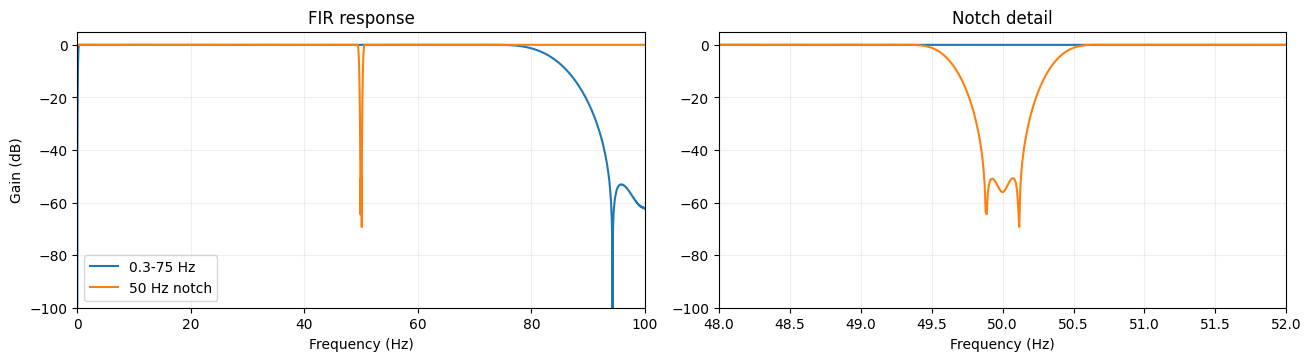

In [13]:
band_kernel = mne.filter.create_filter(None, reader.sfreq, .3, 75., verbose=False)
notch_kernel = mne.filter.create_filter(None, reader.sfreq, [50.625], [49.375],
                                       l_trans_bandwidth=.5, h_trans_bandwidth=.5, verbose=False)
required_context = ((len(band_kernel)-1)+(len(notch_kernel)-1))/(2*reader.sfreq) + 10/TARGET
assert config['context_seconds'] >= required_context

band_uv = mne.filter.filter_data(raw_uv, reader.sfreq, .3, 75., method='fir', phase='zero',
                                fir_design='firwin', pad='reflect_limited', n_jobs=1, verbose=False)
notch_uv = mne.filter.notch_filter(band_uv, reader.sfreq, [50.], method='fir', phase='zero',
                                  notch_widths=.25, trans_bandwidth=1., fir_design='firwin',
                                  pad='reflect_limited', n_jobs=1, verbose=False)
resampled_uv = signal.resample_poly(notch_uv, ratio.numerator, ratio.denominator, axis=-1)
canonical_uv = prep.filter_and_resample(raw_uv, reader.sfreq, TARGET)
np.testing.assert_allclose(resampled_uv, canonical_uv, rtol=0, atol=1e-10)
del canonical_uv

stage_arrays = {'raw': (raw_uv, reader.sfreq), 'bandpass': (band_uv, reader.sfreq),
                'notch': (notch_uv, reader.sfreq), 'resampled': (resampled_uv, TARGET)}
display(pd.DataFrame([{'stage': name, 'shape': str(x.shape), 'sampling_Hz': fs,
                       'unit': 'uV', 'finite': bool(np.isfinite(x).all())}
                      for name, (x, fs) in stage_arrays.items()]))
print(f'带通 {len(band_kernel)} 点；陷波 {len(notch_kernel)} 点；'
      f'所需上下文 ≥{required_context:.2f} 秒，实际 {config["context_seconds"]} 秒')
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), layout='constrained')
for kernel, name in [(band_kernel, '0.3-75 Hz'), (notch_kernel, '50 Hz notch')]:
    f, h = signal.freqz(kernel, worN=65536, fs=reader.sfreq)
    for ax in axes:
        ax.plot(f, 20*np.log10(np.maximum(np.abs(h), 1e-8)), label=name)
axes[0].set(xlim=(0, 100), ylim=(-100, 5), xlabel='Frequency (Hz)', ylabel='Gain (dB)', title='FIR response')
axes[1].set(xlim=(48, 52), ylim=(-100, 5), xlabel='Frequency (Hz)', title='Notch detail')
axes[0].legend()
plt.show()

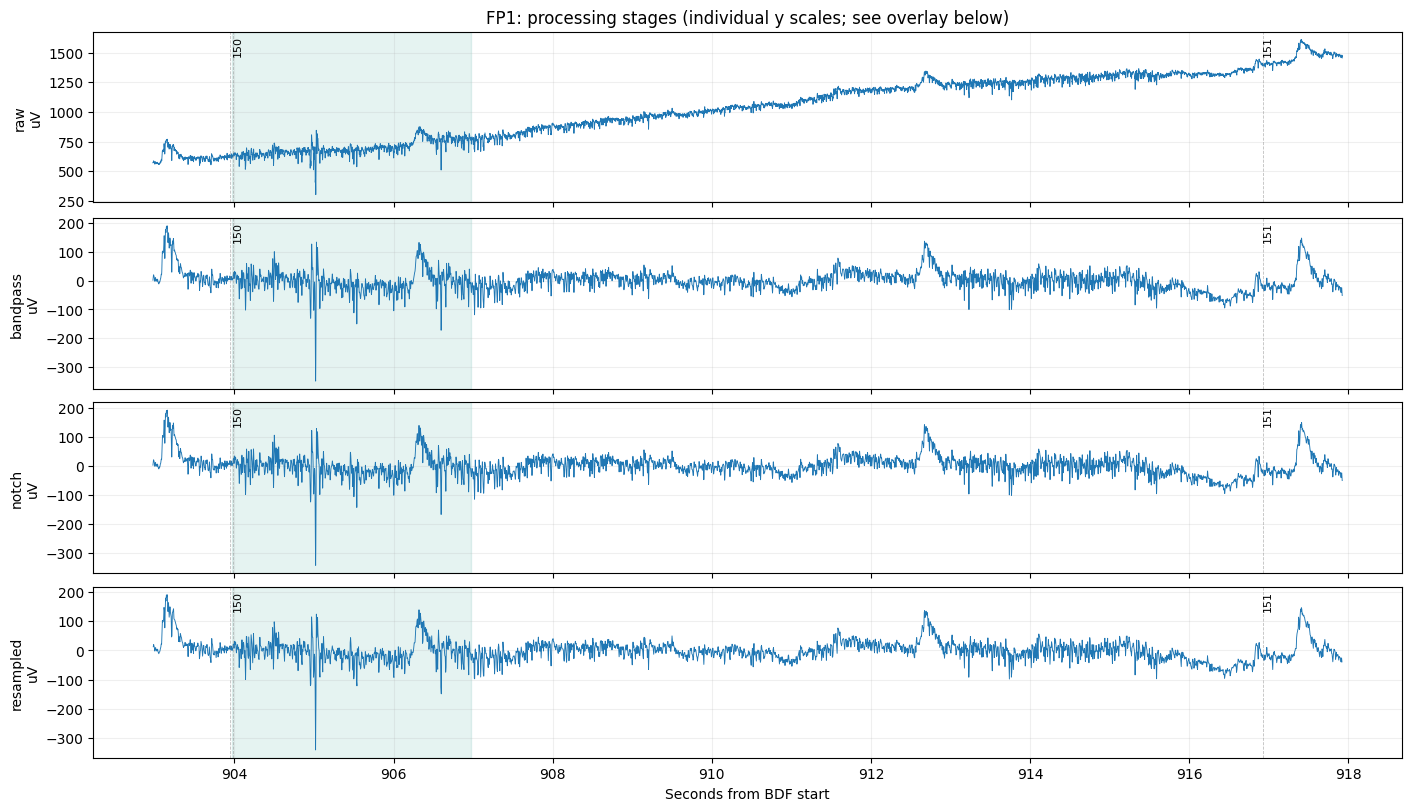

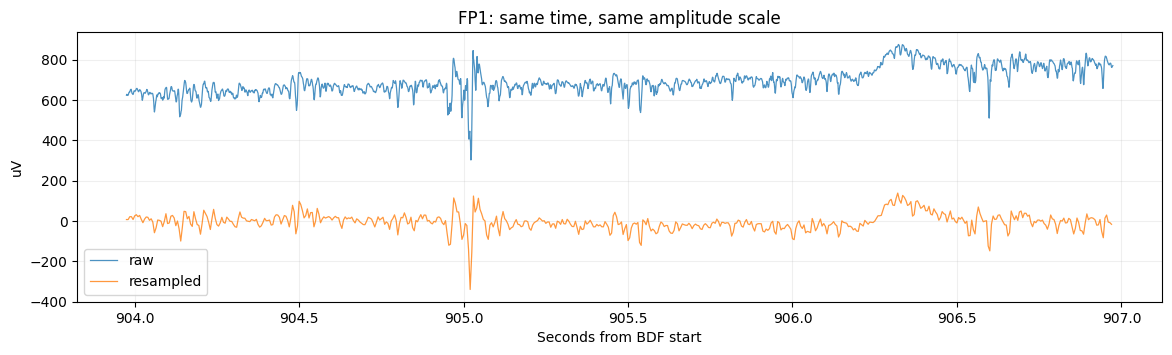

In [14]:
channel = selected_channels[0]
ch = prep.CHANNELS.index(channel)
fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True, layout='constrained')
for ax, (name, (x, fs)) in zip(axes, stage_arrays.items()):
    t = raw_start/reader.sfreq + np.arange(x.shape[1])/fs
    keep = (t >= preview_start) & (t < preview_stop)
    ax.plot(t[keep], x[ch, keep], lw=.65)
    ax.axvspan(demo.start_time, demo.stop_time, alpha=.12, color='#2a9d8f')
    mark_events(ax, preview_start, preview_stop)
    ax.set_ylabel(f'{name}\nuV')
axes[0].set_title(f'{channel}: processing stages (individual y scales; see overlay below)')
axes[-1].set_xlabel('Seconds from BDF start')
plt.show()

# 同一纵轴叠加，避免只由各自自动缩放造成“改善”的错觉。
fig, ax = plt.subplots(figsize=(14, 3.5))
for name in ('raw', 'resampled'):
    x, fs = stage_arrays[name]
    t = raw_start/reader.sfreq + np.arange(x.shape[1])/fs
    keep = (t >= demo.start_time) & (t < demo.stop_time)
    ax.plot(t[keep], x[ch, keep], lw=.9, alpha=.8, label=name)
ax.set(xlabel='Seconds from BDF start', ylabel='uV', title=f'{channel}: same time, same amplitude scale')
ax.legend()
plt.show()

## 6. 频谱与时频对照：滤掉了什么

Welch PSD 在同一个展示区间计算，窗长最多 4 秒、50% 重叠；先对各通道算 PSD，再画中位数
及 10%–90% 分位带。PSD 单位为 μV²/Hz，dB 是 `10 log10(PSD / 1 μV²/Hz)`。
看 50 Hz 附近变化及高低频变化；曲线下降不等同于保留了更多有效脑电。

时频图使用相同色阶、同一通道和相同真实时间，展示滤波后 μV，**不使用归一化后的数据**。
这里只做描述性比较，不把某个频带或颜色直接解释为情绪，也不声称估计了真实 SNR。

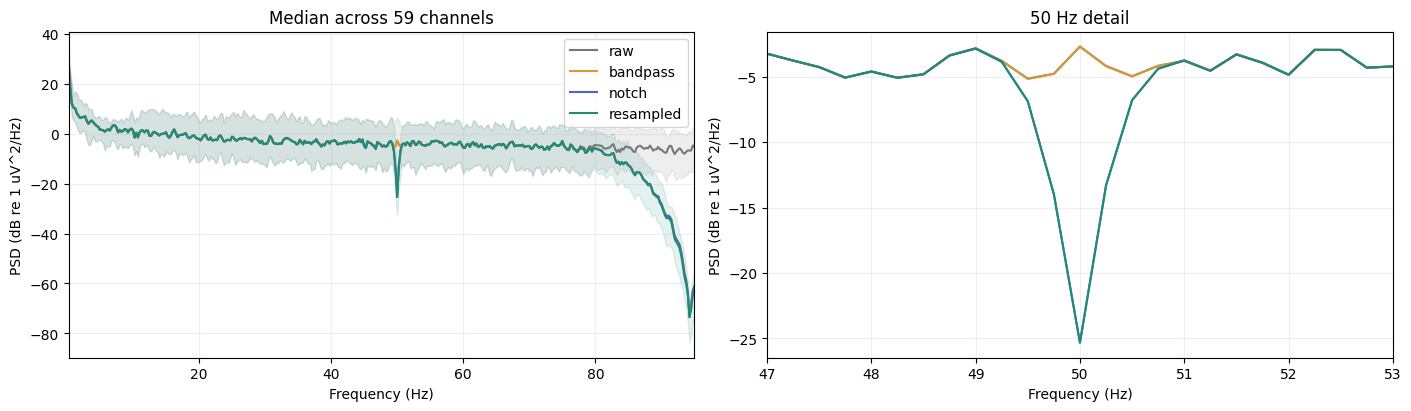

,band,raw_median_uV2,processed_median_uV2,median_paired_change_dB
0,1-4 Hz,16.614556,16.593068,-0.016003
1,4-8 Hz,7.329002,7.313063,-0.009287
2,8-13 Hz,7.275976,7.290477,0.007617
3,13-30 Hz,15.095881,15.073213,-0.005919
4,30-45 Hz,7.593170,7.586254,-0.002806
5,49-51 Hz,0.870291,0.434879,-2.635537


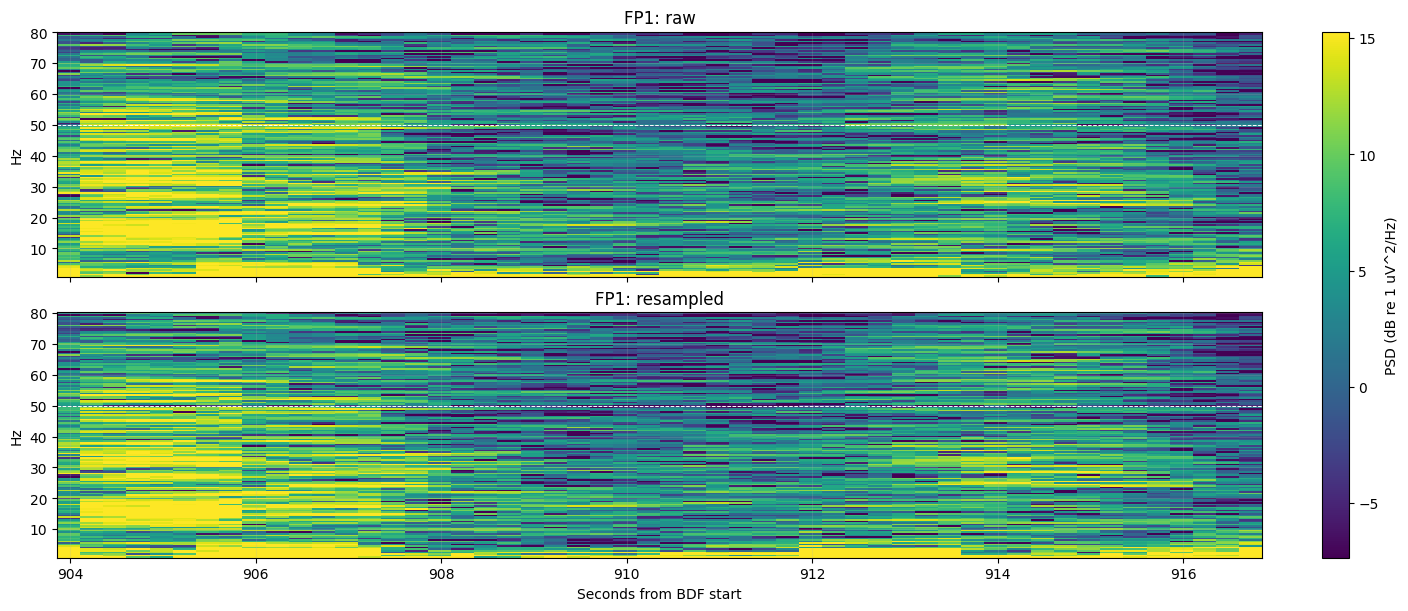

In [15]:
spectra = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
stage_colors = {'raw': '#777777', 'bandpass': '#d99a35', 'notch': '#4a69bd', 'resampled': '#218c74'}
for name, (x, fs) in stage_arrays.items():
    t = raw_start/reader.sfreq + np.arange(x.shape[1])/fs
    x_show = x[:, (t >= preview_start) & (t < preview_stop)]
    nperseg = min(round(4*fs), x_show.shape[1])
    f, p = signal.welch(x_show, fs=fs, nperseg=nperseg, noverlap=nperseg//2, axis=-1)
    spectra[name] = (f, p)
    for ax, bounds in zip(axes, [(.25, 95), (47, 53)]):
        visible = (f >= bounds[0]) & (f <= bounds[1])
        ax.plot(f[visible], 10*np.log10(np.maximum(np.median(p, axis=0)[visible], 1e-20)),
                label=name, color=stage_colors[name])
    if name in ('raw', 'resampled'):
        low, high = np.percentile(p, [10, 90], axis=0)
        visible = (f >= .25) & (f <= 95)
        axes[0].fill_between(f[visible], 10*np.log10(np.maximum(low[visible], 1e-20)),
                             10*np.log10(np.maximum(high[visible], 1e-20)), color=stage_colors[name], alpha=.12)
axes[0].set(xlim=(.25, 95), xlabel='Frequency (Hz)', ylabel='PSD (dB re 1 uV^2/Hz)', title='Median across 59 channels')
axes[1].set(xlim=(47, 53), xlabel='Frequency (Hz)', ylabel='PSD (dB re 1 uV^2/Hz)', title='50 Hz detail')
axes[0].legend()
plt.show()

def band_power(f, p, lo, hi):
    # 插值到精确边界后积分，避免边界频点被漏计。
    grid = np.r_[lo, f[(f > lo) & (f < hi)], hi]
    values = np.vstack([np.interp(grid, f, row) for row in np.atleast_2d(p)])
    return np.trapz(values, grid, axis=-1)

power_rows = []
for label, lo, hi in [('1-4 Hz', 1, 4), ('4-8 Hz', 4, 8), ('8-13 Hz', 8, 13),
                       ('13-30 Hz', 13, 30), ('30-45 Hz', 30, 45), ('49-51 Hz', 49, 51)]:
    before = band_power(*spectra['raw'], lo, hi)
    after = band_power(*spectra['resampled'], lo, hi)
    power_rows.append({'band': label, 'raw_median_uV2': np.median(before),
                       'processed_median_uV2': np.median(after),
                       'median_paired_change_dB': np.median(10*np.log10(np.maximum(after, 1e-20)/np.maximum(before, 1e-20)))})
display(pd.DataFrame(power_rows))

tf = []
for name in ('raw', 'resampled'):
    x, fs = stage_arrays[name]
    t = raw_start/reader.sfreq+np.arange(x.shape[1])/fs
    keep = (t >= preview_start) & (t < preview_stop)
    clip = x[ch, keep]
    n = min(round(2*fs), len(clip))
    f, tt, p = signal.spectrogram(clip, fs=fs, nperseg=n, noverlap=n-round(.25*fs))
    keep_f = (f >= 1) & (f <= 80)
    tf.append((name, f[keep_f], tt+t[keep][0], 10*np.log10(np.maximum(p[keep_f], 1e-20))))
vmin, vmax = np.percentile(np.concatenate([x[3].ravel() for x in tf]), [5, 95])
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, layout='constrained')
for ax, (name, f, tt, p) in zip(axes, tf):
    mesh = ax.pcolormesh(tt, f, p, shading='auto', vmin=vmin, vmax=vmax, cmap='viridis')
    ax.axhline(50, color='white', ls='--', lw=.7)
    ax.set(ylabel='Hz', title=f'{channel}: {name}')
axes[-1].set_xlabel('Seconds from BDF start')
fig.colorbar(mesh, ax=axes, label='PSD (dB re 1 uV^2/Hz)')
plt.show()

## 7. 切出 3 秒、计算质控，再归一化

质控使用**滤波/重采样后、裁剪前的 μV**，按全部 59×600 个数值计算：

| 项目 | 当前规则 |
|---|---|
| 长度/有限值 | 必须恰好 600 点/通道且全有限；否则报错，不生成伪造的补零窗 |
| 大幅值占比 | `mean(abs(x_uV) > 200)` **> 1%** 才失败（等于 1% 不失败） |
| 平坦通道 | 任一道 `std <= 1e-4 μV` 失败 |
| 峰峰值 PTP | 保存为诊断指标；当前不按 500 μV 拒绝 |
| 归一化 | `clip(x_uV/200, -1, 1)`，float32；裁剪后不能完整反推出 μV |

1% 是本项目初步阈值，不是 dataset-rules 仓库强制标准。通过只表示通过这些规则，
不保证没有眼动、肌电、运动等伪迹；目前没有 ICA 或坏道插值。

,示例窗口 QC
qc_pass,True
qc_reasons,[]
clip_fraction,0.000311
maximum_ptp_uv,565.22387
minimum_channel_std_uv,3.126246


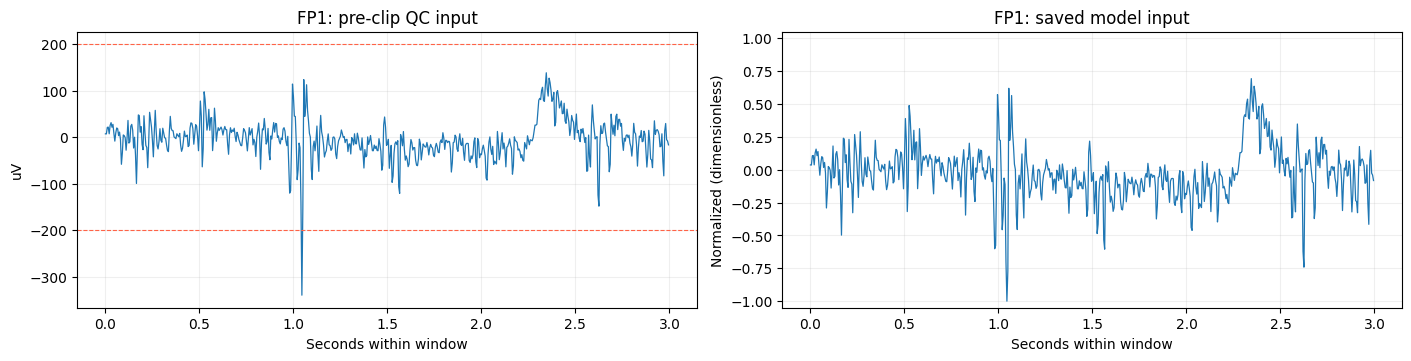

70633

In [16]:
a, b = int(demo.start)-output_offset, int(demo.stop)-output_offset
demo_filtered = resampled_uv[:, a:b]
demo_normalized, demo_qc = prep.encode_window(demo_filtered,
                                             max_clip_fraction=config['max_clip_fraction'],
                                             flat_std_uv=config['flat_std_uv'])
assert demo_normalized.shape == (59, 600)
assert np.isfinite(demo_normalized).all() and np.abs(demo_normalized).max() <= 1
display(pd.Series({k: v for k, v in demo_qc.items() if k != 'bad_channel_mask'}, name='示例窗口 QC').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), layout='constrained')
relative_t = np.arange(600)/TARGET
axes[0].plot(relative_t, demo_filtered[ch], lw=.9)
for level in [-200, 200]:
    axes[0].axhline(level, color='tomato', ls='--', lw=.8)
axes[0].set(xlabel='Seconds within window', ylabel='uV', title=f'{channel}: pre-clip QC input')
axes[1].plot(relative_t, demo_normalized[ch], lw=.9)
axes[1].set(xlabel='Seconds within window', ylabel='Normalized (dimensionless)', ylim=(-1.05, 1.05),
            title=f'{channel}: saved model input')
plt.show()

# 仅保留一个块的原始与最终 μV；中间带通、陷波数组已完成展示，可释放。
del stage_arrays, band_uv, notch_uv
gc.collect()

## 8. 全部可用窗口复算：原始 vs 处理后，并逐点对照 Lance

这部分会花费最多时间：遍历当前 BDF 的全部可用窗口所属块（包括休息），每次仅持有一个块。
对相同时间区间分别计算原始和处理后幅度统计；使用原始采样率与 200 Hz 各自的样本数作为分母。
**原始大幅值占比只是比较指标，不是生产拒绝标准**。原始 DC 偏移也会使该指标较高。

每窗调用 `encode_window`，核对 Lance 的实际信号、标签/边界、QC 结果、clip fraction、PTP、
标准差与坏道 mask。跨版本浮点容差为 rtol=1e-6、atol=1e-7（归一化单位）；另报告
完全逐点一致的窗口数，不把“容差内一致”说成逐位一致。
只保留每窗/每通道的小型统计，以及代表性好/差窗口，正式输出不变。

In [17]:
metadata_columns = [name for name in dataset.schema.names if name != 'data']
stored = dataset.to_table(columns=metadata_columns, scan_in_order=True).to_pandas()
stored['lance_row'] = np.arange(len(stored))
stored = stored.set_index('output_start_sample', drop=False).loc[windows.start.to_numpy()].reset_index(drop=True)
assert len(stored) == len(plan) and stored.output_start_sample.is_unique
np.testing.assert_array_equal(stored.output_stop_sample, windows.stop)
np.testing.assert_array_equal(stored.label_name, windows.label_name)
np.testing.assert_allclose(stored.start_time, windows.start_time, rtol=0, atol=1e-10)
assert stored.duration.eq(3).all() and stored.valid_length.eq(59*600).all()
assert stored.source_sfreq.eq(reader.sfreq).all()
np.testing.assert_array_equal(stored.start_sample, np.rint(windows.start*reader.sfreq/TARGET).astype('int64'))
np.testing.assert_array_equal(stored.stop_sample, np.rint(windows.stop*reader.sfreq/TARGET).astype('int64'))
assert all(list(x) == [59, 600] for x in stored['shape'])
assert all(list(x) == [59, 600] for x in stored['original_shape'])
assert all(list(x) == list(prep.CHANNELS) for x in stored.channel_names)
for i, w in enumerate(plan):
    seg = report['segments'][w['segment_index']]
    row = stored.iloc[i]
    assert split_s3(row.source_path) == split_s3(RAW_URI)
    assert row.events_uri == seg['events_uri']
    assert row.label == prep.PRIMARY_LABEL_IDS[windows.loc[i, 'label_name']]
    if seg['segment_type'] == 'rest':
        assert pd.isna(row.emotion_label)
    else:
        assert row.emotion_label == seg['emotion_label_id']

good_candidates = stored.index[stored.qc_pass & stored.segment_type.eq('emotion')].tolist()
if not good_candidates:
    good_candidates = stored.index[stored.qc_pass].tolist()
example_indices = {demo_index}
if good_candidates:
    typical_good = min(good_candidates, key=lambda i: abs(stored.loc[i, 'maximum_ptp_uv']-
                        stored.loc[good_candidates, 'maximum_ptp_uv'].median()))
    example_indices.add(typical_good)
failed_indices = stored.index[~stored.qc_pass].tolist()
# 所有失败窗仍会审计；波形只保留最多两段失败代表和一段典型通过片段。
example_indices.update(sorted(failed_indices, key=lambda i: stored.loc[i, 'clip_fraction'], reverse=True)[:2])
if not failed_indices:
    example_indices.add(int(stored.clip_fraction.idxmax()))

audit_rows, examples = [], {}
raw_channel_clip = np.empty((len(plan), len(prep.CHANNELS)))
post_channel_clip = np.empty_like(raw_channel_clip)
raw_channel_std = np.empty_like(raw_channel_clip)
post_channel_std = np.empty_like(raw_channel_clip)
exact_count, max_error = 0, 0.
started = datetime.now(ZoneInfo(TIMEZONE))
for block_no, (block_id, indices) in enumerate(groups.items(), 1):
    start, stop, offset = block_bounds(indices)
    if block_id == demo_block:
        source, filtered = raw_uv, resampled_uv
    else:
        source = reader.read_samples(start, stop)
        filtered = prep.filter_and_resample(source, reader.sfreq, TARGET)
    remote = dataset.take(stored.loc[indices, 'lance_row'].astype(int).tolist(), columns=['data'])
    remote_values = np.asarray(remote.column('data').combine_chunks().values).reshape(len(indices), 59, 600)
    for j, i in enumerate(indices):
        w = plan[i]
        left = round(w['start']*reader.sfreq/TARGET)-start
        right = round(w['stop']*reader.sfreq/TARGET)-start
        before = source[:, left:right]
        after = filtered[:, w['start']-offset:w['stop']-offset]
        encoded, qc = prep.encode_window(after, max_clip_fraction=config['max_clip_fraction'],
                                         flat_std_uv=config['flat_std_uv'])
        np.testing.assert_allclose(encoded, remote_values[j], rtol=1e-6, atol=1e-7,
                                   err_msg=f'窗口 {i} 与 Lance 波形不一致')
        error = float(np.max(np.abs(encoded-remote_values[j])))
        max_error = max(max_error, error)
        exact_count += int(np.array_equal(encoded, remote_values[j]))
        expected = stored.iloc[i]
        assert qc['qc_pass'] == expected.qc_pass
        assert qc['qc_reasons'] == list(expected.qc_reasons)
        np.testing.assert_array_equal(qc['bad_channel_mask'], expected.bad_channel_mask)
        for field in ['clip_fraction', 'maximum_ptp_uv', 'minimum_channel_std_uv']:
            np.testing.assert_allclose(qc[field], expected[field], rtol=1e-6, atol=1e-7)
        raw_channel_clip[i] = np.mean(np.abs(before)>200, axis=1)
        post_channel_clip[i] = np.mean(np.abs(after)>200, axis=1)
        raw_channel_std[i], post_channel_std[i] = before.std(axis=1), after.std(axis=1)
        audit_rows.append(dict(index=i, start_time=w['start']/TARGET, label_name=expected.label_name,
                               raw_clip_fraction=float(raw_channel_clip[i].mean()),
                               raw_maximum_ptp_uv=float(np.ptp(before, axis=1).max()),
                               raw_median_std_uv=float(np.median(raw_channel_std[i])),
                               post_median_std_uv=float(np.median(post_channel_std[i])),
                               lance_max_abs_error=error,
                               **{k: v for k, v in qc.items() if k != 'bad_channel_mask'}))
        if i in example_indices:
            examples[i] = {'raw': before.copy(), 'filtered': after.copy(), 'normalized': encoded.copy()}
    del source, filtered, remote, remote_values
    if block_no == 1 or block_no % 5 == 0 or block_no == len(groups):
        print(f'完成块 {block_no}/{len(groups)}；复核窗口 {len(audit_rows)}/{len(plan)}', flush=True)
audit = pd.DataFrame(audit_rows).set_index('index').sort_index()
assert len(audit) == len(plan) and audit.qc_pass.sum() == saved['qc_pass_count']
elapsed = (datetime.now(ZoneInfo(TIMEZONE))-started).total_seconds()
print(f'完成：{len(audit)} 窗口；逐点完全一致 {exact_count}；最大归一化误差 {max_error:.3g}；耗时 {elapsed:.1f} 秒')
display(audit.groupby('label_name').agg(total=('qc_pass', 'size'), passed=('qc_pass', 'sum'),
                                       median_clip_fraction=('clip_fraction', 'median')))

完成块 1/34；复核窗口 4/273
完成块 5/34；复核窗口 21/273
完成块 10/34；复核窗口 58/273
完成块 15/34；复核窗口 97/273
完成块 20/34；复核窗口 147/273
完成块 25/34；复核窗口 187/273
完成块 30/34；复核窗口 243/273
完成块 34/34；复核窗口 273/273
完成：273 窗口；逐点完全一致 273；最大归一化误差 0；耗时 25.9 秒


,total,passed,median_clip_fraction
label_name,,,
negative,85,85,0.0
neutral,76,76,0.0
positive,77,77,0.0
rest,35,33,0.0


## 9. 全窗口质量分布与通道定位

第一组图在真实 BDF 时间轴上给出大幅值占比和失败点；空白处没有可用窗口。
前后 PTP / 标准差的散点使用相同窗口配对，虚线是“前后相等”。
热图按窗口序号排列，**不表示连续均匀时间**；同一色阶可看出是否集中在少数通道或某些窗口。
通道热图没有新增“某道 >1% 就整窗失败”的规则：生产大幅值规则仍是所有通道样本的总体占比。

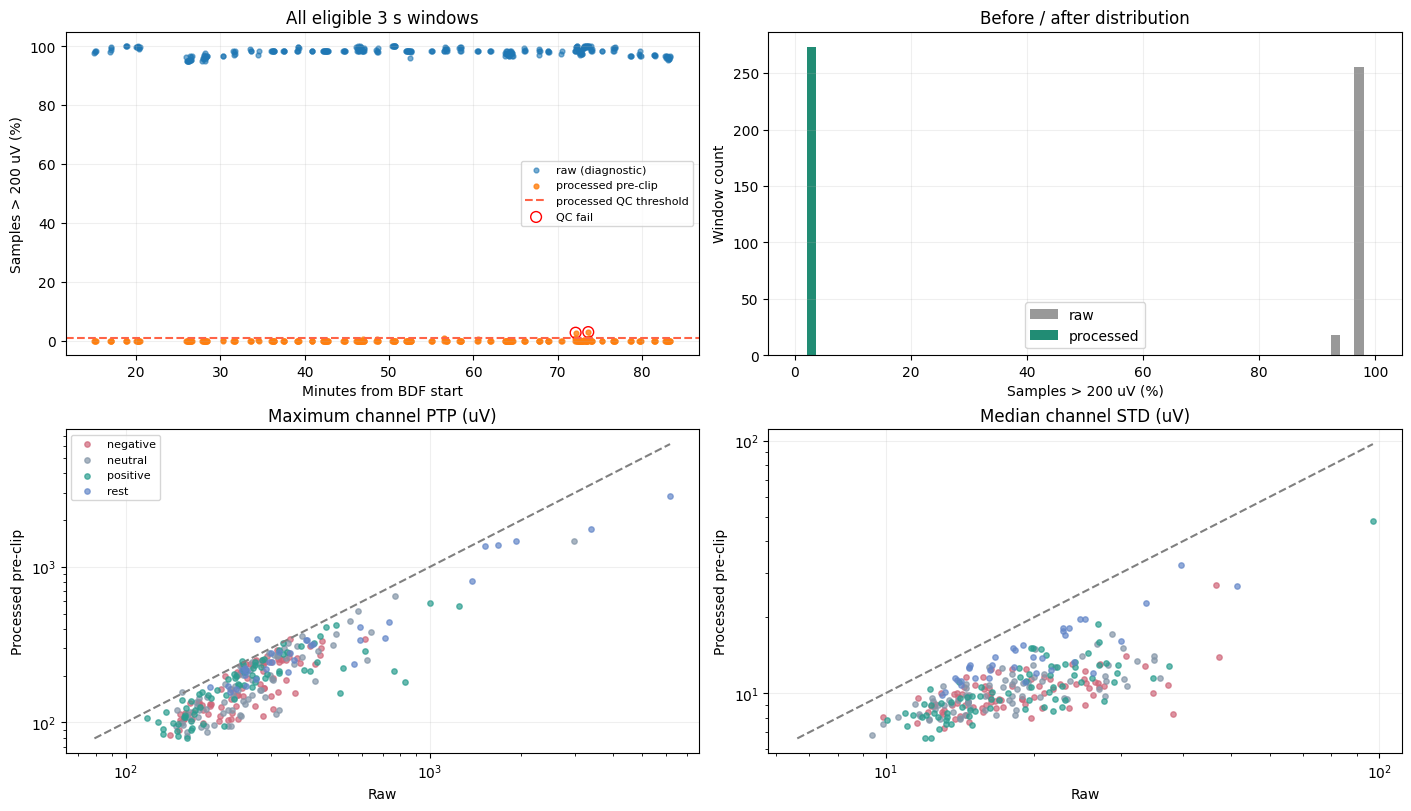

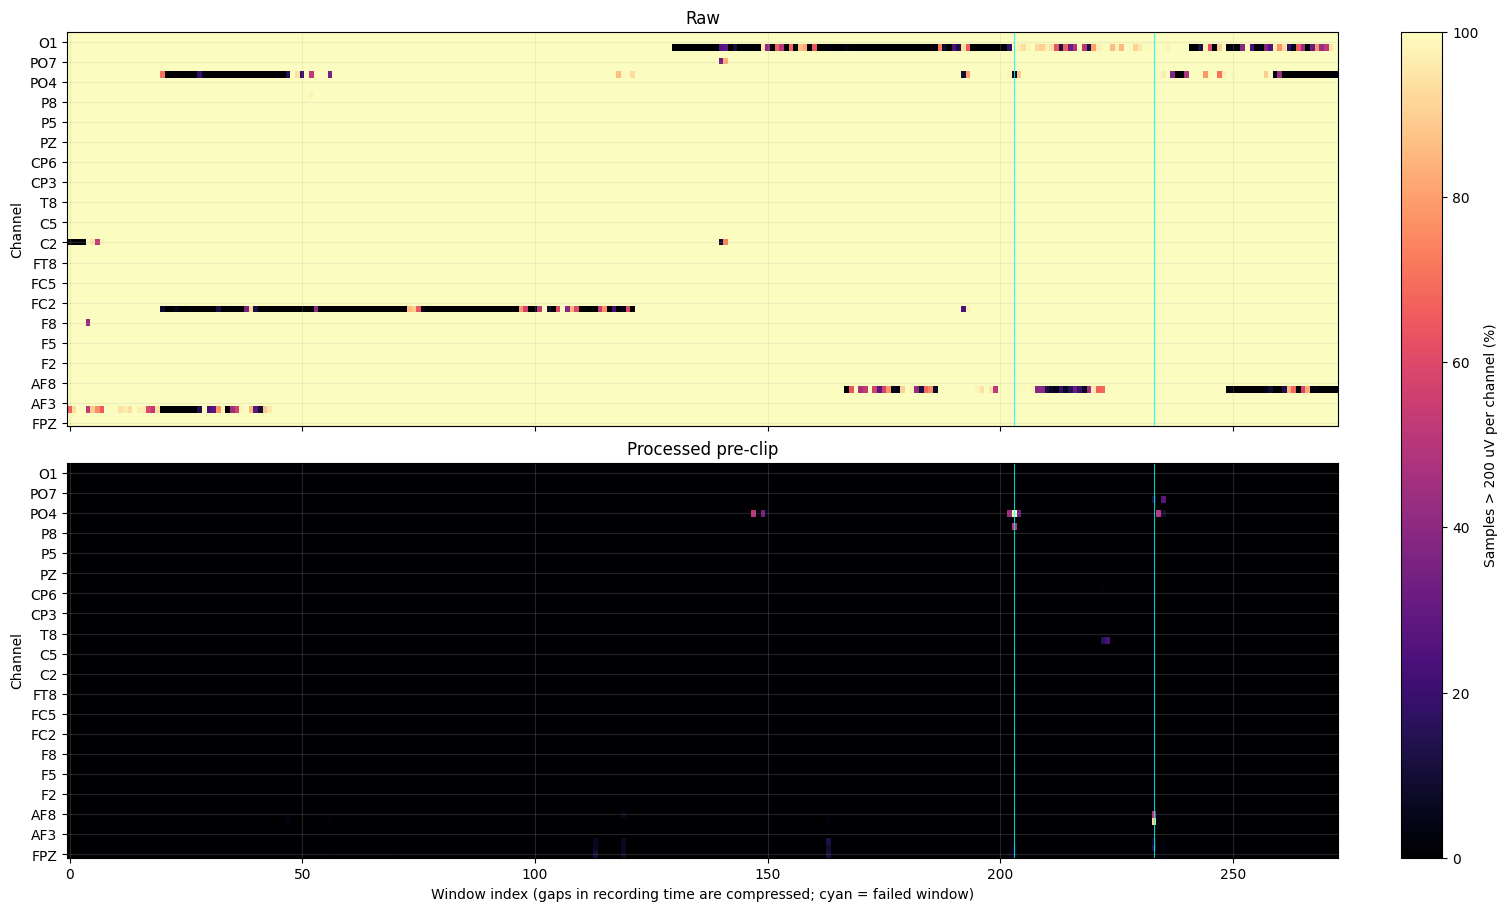

,channel,mean_raw_clip_percent,mean_processed_clip_percent,max_processed_clip_percent,flat_window_count
51,PO4,100.000000,1.170940,98.500000,0
5,AF7,85.085714,0.378510,91.166667,0
6,AF8,100.000000,0.221001,49.666667,0
49,POZ,99.992186,0.190476,49.666667,0
1,FP1,100.000000,0.189866,13.166667,0
2,FP2,93.685592,0.167888,13.000000,0
0,FPZ,100.000000,0.164225,11.000000,0
53,PO6,100.000000,0.149573,28.000000,0
32,T7,100.000000,0.145910,23.333333,0
55,PO8,100.000000,0.007937,2.166667,0


,start_time,label_name,clip_fraction,maximum_ptp_uv,minimum_channel_std_uv,qc_reasons,wall_start
index,,,,,,,
203,4327.26,rest,0.027175,1378.896424,3.493593,[clip_fraction_above_threshold],2026-10-22 17:25:26.260000+08:00
233,4417.26,rest,0.029350,1467.919074,4.324911,[clip_fraction_above_threshold],2026-10-22 17:26:56.260000+08:00


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout='constrained')
axes[0, 0].scatter(audit.start_time/60, audit.raw_clip_fraction*100, s=12, alpha=.6, label='raw (diagnostic)')
axes[0, 0].scatter(audit.start_time/60, audit.clip_fraction*100, s=12, alpha=.8, label='processed pre-clip')
axes[0, 0].axhline(config['max_clip_fraction']*100, color='tomato', ls='--', label='processed QC threshold')
bad = audit[~audit.qc_pass]
axes[0, 0].scatter(bad.start_time/60, bad.clip_fraction*100, s=60, facecolors='none', edgecolors='red', label='QC fail')
axes[0, 0].set(xlabel='Minutes from BDF start', ylabel='Samples > 200 uV (%)', title='All eligible 3 s windows')
axes[0, 0].legend(fontsize=8)
axes[0, 1].hist([audit.raw_clip_fraction*100, audit.clip_fraction*100], bins=25,
                label=['raw', 'processed'], color=['#999999', '#218c74'])
axes[0, 1].set(xlabel='Samples > 200 uV (%)', ylabel='Window count', title='Before / after distribution')
axes[0, 1].legend()
for ax, before, after, title in [(axes[1, 0], 'raw_maximum_ptp_uv', 'maximum_ptp_uv', 'Maximum channel PTP (uV)'),
                                  (axes[1, 1], 'raw_median_std_uv', 'post_median_std_uv', 'Median channel STD (uV)')]:
    for label, group in audit.groupby('label_name'):
        ax.scatter(group[before], group[after], s=15, alpha=.7, color=COLORS[label], label=label)
    lo = max(min(audit[before].min(), audit[after].min()), 1e-8)
    hi = max(audit[before].max(), audit[after].max())
    ax.plot([lo, hi], [lo, hi], ls='--', color='gray')
    ax.set(xscale='log', yscale='log', xlabel='Raw', ylabel='Processed pre-clip', title=title)
axes[1, 0].legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True, layout='constrained')
vmax = max(float(raw_channel_clip.max()*100), float(post_channel_clip.max()*100), .1)
for ax, values, title in zip(axes, [raw_channel_clip, post_channel_clip], ['Raw', 'Processed pre-clip']):
    mesh = ax.imshow(values.T*100, origin='lower', aspect='auto', interpolation='nearest',
                     vmin=0, vmax=vmax, cmap='magma')
    ax.set(yticks=range(0, 59, 3), yticklabels=prep.CHANNELS[::3], ylabel='Channel', title=title)
    for i in failed_indices:
        ax.axvline(i, color='cyan', lw=.8, alpha=.8)
axes[-1].set_xlabel('Window index (gaps in recording time are compressed; cyan = failed window)')
fig.colorbar(mesh, ax=axes, label='Samples > 200 uV per channel (%)')
plt.show()
channel_qc = pd.DataFrame({'channel': prep.CHANNELS,
                           'mean_raw_clip_percent': raw_channel_clip.mean(axis=0)*100,
                           'mean_processed_clip_percent': post_channel_clip.mean(axis=0)*100,
                           'max_processed_clip_percent': post_channel_clip.max(axis=0)*100,
                           'flat_window_count': (post_channel_std <= config['flat_std_uv']).sum(axis=0)})
display(channel_qc.sort_values('mean_processed_clip_percent', ascending=False).head(12))
failed_table = audit.loc[~audit.qc_pass, ['start_time', 'label_name', 'clip_fraction',
                                        'maximum_ptp_uv', 'minimum_channel_std_uv', 'qc_reasons']].copy()
failed_table['wall_start'] = wall_time(failed_table.start_time)
display(failed_table if len(failed_table) else Markdown('这一份录制没有触发当前规则的失败窗口。'))

## 10. 看具体波形：典型通过窗口与最差窗口

典型通过样本从通过的情绪窗中选取最接近其中位 PTP 的一窗；失败样本取大幅值占比最高的
最多两窗。如果没有失败窗，则展示大幅值占比最高窗并保留它的真实通过状态。
每个样本选择其处理后大幅值占比最高的通道（并列时取 PTP 较高者），帮助定位异常。
不同样本可能展示不同通道，标题注明通道名；右列展示归一化造成的饱和，不用来计算 QC。

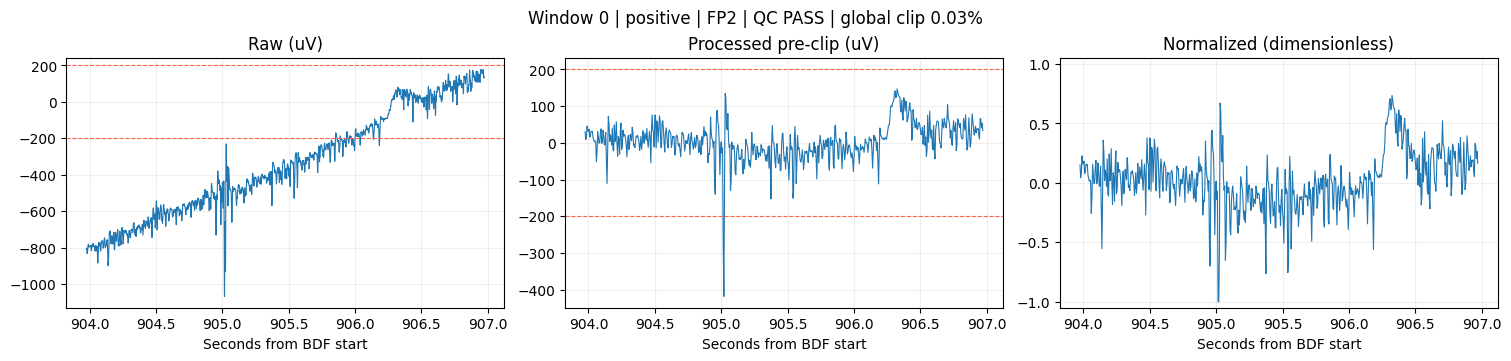

{'window': 0,
 'channel': 'FP2',
 'absolute_start': '2026-10-22 16:28:22.975000+08:00',
 'qc_pass': True,
 'reasons': []}

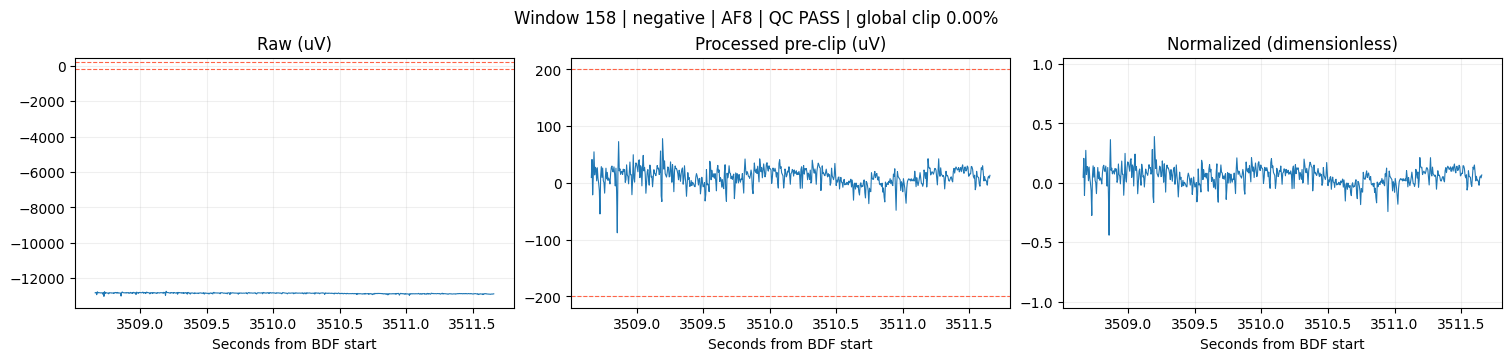

{'window': 158,
 'channel': 'AF8',
 'absolute_start': '2026-10-22 17:11:47.660000+08:00',
 'qc_pass': True,
 'reasons': []}

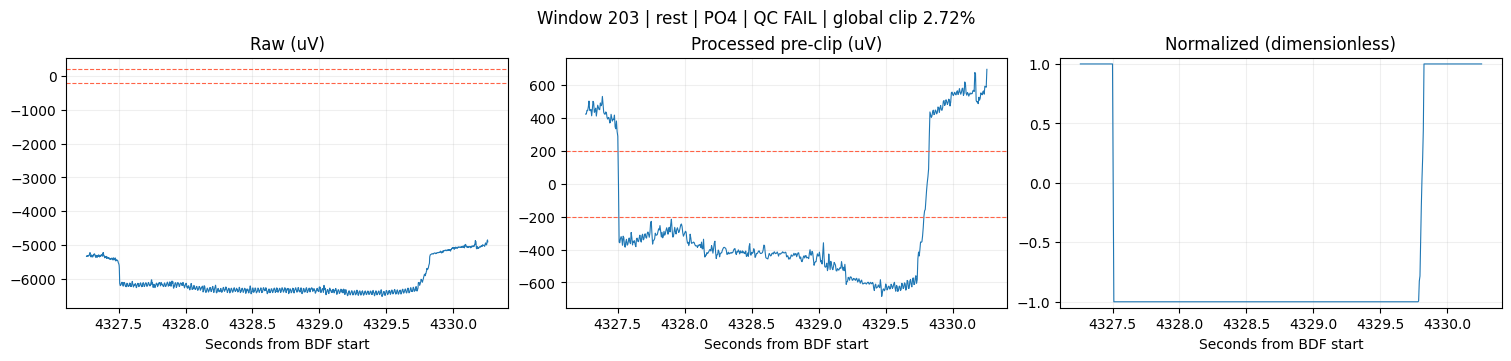

{'window': 203,
 'channel': 'PO4',
 'absolute_start': '2026-10-22 17:25:26.260000+08:00',
 'qc_pass': False,
 'reasons': ['clip_fraction_above_threshold']}

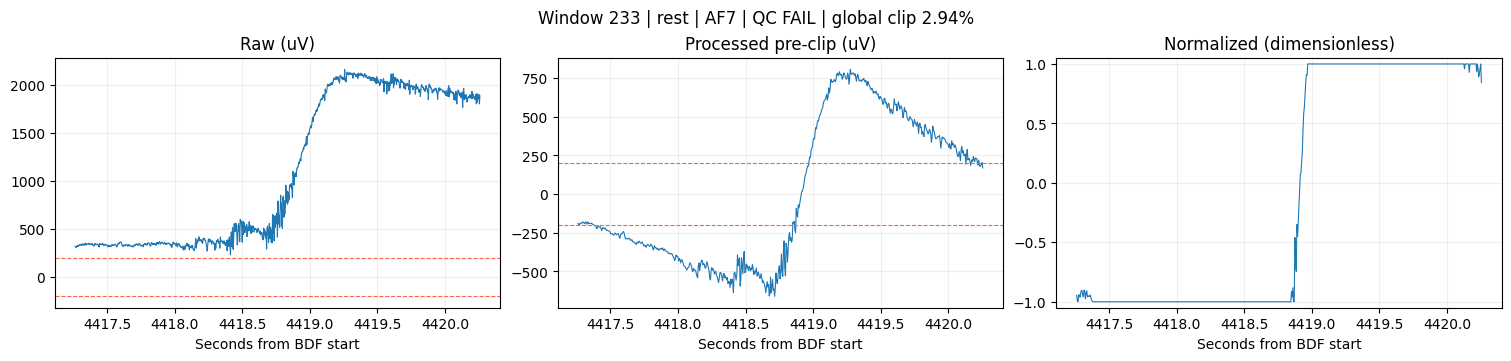

{'window': 233,
 'channel': 'AF7',
 'absolute_start': '2026-10-22 17:26:56.260000+08:00',
 'qc_pass': False,
 'reasons': ['clip_fraction_above_threshold']}

In [19]:
def plot_window_detail(index, channel=None):
    index = int(index)
    if index not in windows.index:
        raise ValueError(f'窗口索引需在 0..{len(windows)-1} 内')
    if index not in examples:
        block_id = int(plan[index]['start']//round(config['block_seconds']*TARGET))
        a, b, offset = block_bounds(groups[block_id])
        source = reader.read_samples(a, b)
        filtered = prep.filter_and_resample(source, reader.sfreq, TARGET)
        w = plan[index]
        original = source[:, round(w['start']*reader.sfreq/TARGET)-a:round(w['stop']*reader.sfreq/TARGET)-a]
        after = filtered[:, w['start']-offset:w['stop']-offset]
        encoded, _ = prep.encode_window(after, max_clip_fraction=config['max_clip_fraction'], flat_std_uv=config['flat_std_uv'])
        example = dict(raw=original, filtered=after, normalized=encoded)
    else:
        example = examples[index]
    if channel is None:
        order = np.lexsort((np.ptp(example['filtered'], axis=1), np.mean(np.abs(example['filtered'])>200, axis=1)))
        c = int(order[-1])
    else:
        c = prep.CHANNELS.index(channel)
    row = audit.loc[index]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), layout='constrained')
    start = row.start_time
    axes[0].plot(start+np.arange(example['raw'].shape[1])/reader.sfreq, example['raw'][c], lw=.8)
    axes[1].plot(start+np.arange(600)/TARGET, example['filtered'][c], lw=.8)
    axes[2].plot(start+np.arange(600)/TARGET, example['normalized'][c], lw=.8)
    for ax in axes[:2]:
        for level in (-200, 200):
            ax.axhline(level, color='tomato', lw=.8, ls='--')
    for ax, title in zip(axes, ['Raw (uV)', 'Processed pre-clip (uV)', 'Normalized (dimensionless)']):
        ax.set(title=title, xlabel='Seconds from BDF start')
    axes[2].set_ylim(-1.05, 1.05)
    fig.suptitle(f"Window {index} | {row.label_name} | {prep.CHANNELS[c]} | "
                  f"QC {'PASS' if row.qc_pass else 'FAIL'} | global clip {row.clip_fraction:.2%}")
    plt.show()
    return dict(window=index, channel=prep.CHANNELS[c], absolute_start=str(wall_time(start)),
                qc_pass=bool(row.qc_pass), reasons=row.qc_reasons)

for i in sorted(example_indices):
    display(plot_window_detail(i))

## 11. 分标签保留比例、覆盖范围与可复现结论

“通过率”以**这一份 BDF 中生成的完整标签窗口**为分母，不是整段录制的可用比例。
rest 是采集状态，不是第四种情绪；训练情绪三分类时还要筛选 `segment_type='emotion'`。
过滤后的数据只说明通过初步幅度/平坦度检查，仍应结合波形和频谱判断残留伪迹。

下面自动生成本次结果，不把示例的计数写死。最后给出生产数据读取方式；Notebook 本身不保存新的波形副本。

,pass,fail,total,pass_rate
label_name,,,,
negative,85,0,85,1.000000
neutral,76,0,76,1.000000
positive,77,0,77,1.000000
rest,33,2,35,0.942857


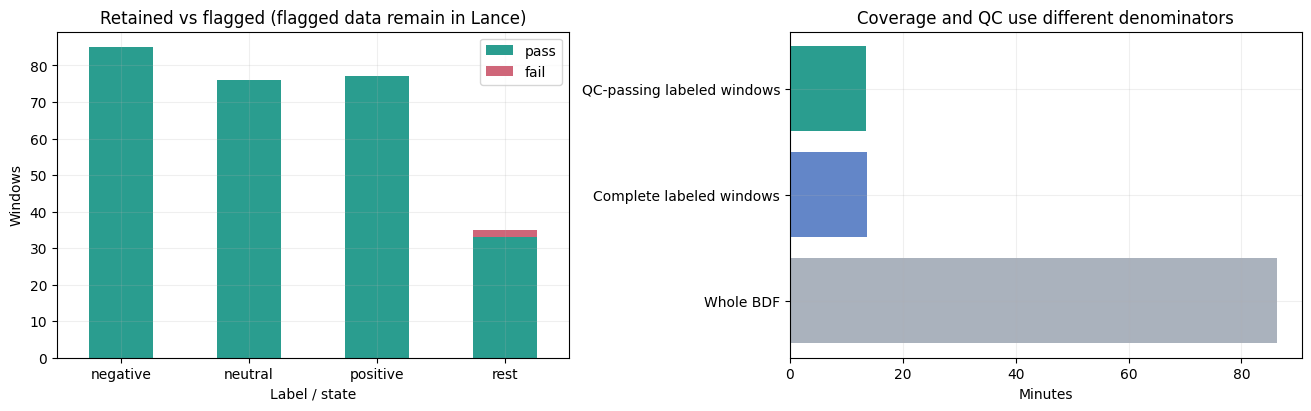

本次复算 **273** 个完整 3 秒窗口，**271** 通过、**2** 未通过；与固定版本 Lance 的 **273** 个窗口完全一致，最大归一化绝对差 **0**。完整窗口仅覆盖 BDF 的 **15.8%**，其余时间不能从当前标签和质控结果推断为可训练数据。

,本次运行记录
raw_uri,s3://oi-data/EMOVID_RAW/20261022161317_20261022_lwh/20261022161317_20261022_lwh/lwh/lw...
lance_uri,s3://personalized-fm/processed/20261022161317_20261022_lwh.lance
lance_version,1
executed_at,2026-11-03T14:50:25.762117+08:00
source_etag_at_run,"""d07c4fb79c83f92ffec08ad32e194724-15"""
mapping_signature,ad1d64ea9d4ca385113af5680e46da5f2ee93204ed5a0faa3097e0a18819a8cb
source_duration_seconds,5181.0
complete_windows,273
qc_pass,271
qc_fail,2


,sample_id,emotion_label,start_time,shape
0,emovid#5dbe735ab8f4977d2f637cea,2,903.975,"[59, 600]"
1,emovid#56acb32e4d9cebb6b5c432c3,2,906.975,"[59, 600]"
2,emovid#082a7241a88237d9434e51cd,2,909.975,"[59, 600]"
3,emovid#92f24b69c454b8b3a0cbd945,2,912.975,"[59, 600]"
4,emovid#6b8be9cb8e17dcdaf0752384,1,1015.635,"[59, 600]"


In [20]:
counts = pd.crosstab(audit.label_name, audit.qc_pass).reindex(columns=[True, False], fill_value=0)
counts.columns = ['pass', 'fail']
counts['total'] = counts['pass']+counts['fail']
counts['pass_rate'] = counts['pass']/counts.total
display(counts)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
counts[['pass', 'fail']].plot.bar(stacked=True, ax=axes[0], color=['#2a9d8f', '#cf6679'], rot=0)
axes[0].set(xlabel='Label / state', ylabel='Windows', title='Retained vs flagged (flagged data remain in Lance)')
axes[1].barh(['Whole BDF', 'Complete labeled windows', 'QC-passing labeled windows'],
              [reader.duration/60, len(audit)*3/60, audit.qc_pass.sum()*3/60], color=['#aab2bd', '#6386c8', '#2a9d8f'])
axes[1].set(xlabel='Minutes', title='Coverage and QC use different denominators')
plt.show()

notebook_summary = {
    'raw_uri': RAW_URI, 'lance_uri': output.uri(NAME+'.lance'), 'lance_version': dataset.version,
    'executed_at': datetime.now(ZoneInfo(TIMEZONE)).isoformat(), 'source_etag_at_run': head['ETag'],
    'mapping_signature': mapping_signature(report), 'source_duration_seconds': reader.duration,
    'complete_windows': len(audit), 'qc_pass': int(audit.qc_pass.sum()),
    'qc_fail': int((~audit.qc_pass).sum()), 'window_seconds': 3, 'padding': False,
    'discarded_tail_seconds': tail_samples/TARGET, 'lance_exact_windows': exact_count,
    'lance_max_absolute_error': max_error,
    'qc_reasons': dict(Counter(reason for reasons in audit.qc_reasons for reason in reasons)),
    'source_code_sha256': {name: hashlib.sha256((PROJECT/'preprocessing'/'common'/name).read_bytes()).hexdigest()
                            for name in ['preprocess_emovid_rules.py', 'emovid_segments.py', 'batch_emovid_segments.py']},
}
display(Markdown(
    f"本次复算 **{len(audit)}** 个完整 3 秒窗口，**{int(audit.qc_pass.sum())}** 通过、"
    f"**{int((~audit.qc_pass).sum())}** 未通过；与固定版本 Lance 的 **{exact_count}** 个窗口完全一致，"
    f"最大归一化绝对差 **{max_error:.3g}**。完整窗口仅覆盖 BDF 的 **{len(audit)*3/reader.duration:.1%}**，"
    f"其余时间不能从当前标签和质控结果推断为可训练数据。"))
display(pd.Series(notebook_summary).drop('source_code_sha256').to_frame('本次运行记录'))

# 生产读取示例：只取少量通过 QC 的情绪窗口；不生成新输出。
training_preview = dataset.to_table(
    filter="qc_pass = true AND segment_type = 'emotion'",
    columns=['sample_id', 'emotion_label', 'start_time', 'shape'], limit=5)
display(training_preview.to_pandas())

## 12. 可选交互浏览与后续复用

已有静态图无需额外插件。若前端支持 ipywidgets，将参数区 `ENABLE_WIDGETS=True` 后运行本格，
可切换窗口和通道；每次点击才读取对应生产块，不在拖动时反复请求 S3。
也可直接调用 `plot_window_detail(窗口序号, 'O1')`。表格 `audit`、`channel_qc`、`events_df`、
`segments`、`windows` 已在内存中，可继续分析；大波形不写到 home。

相关实现：[统一入口](../preprocessing/common/emovid_pipeline.py)、[数值处理](../preprocessing/common/preprocess_emovid_rules.py)、
[映射实现](../preprocessing/common/emovid_segments.py)、[预处理说明及与 official_subjects 的差异](../EMOVID_PREPROCESSING.rst)。
生产参数来源、项目自选阈值与未执行步骤均以这些文件为准。

本 Notebook 针对当前 3 秒、59 通道、200 Hz、μV 已确认的 EMOVID 数据契约。
更改预处理配方后，应先通过统一入口生成相应数据，再重新运行对照，不通过调整容差掩盖变化。

In [17]:
if ENABLE_WIDGETS:
    import ipywidgets as widgets
    index_control = widgets.BoundedIntText(value=demo_index, min=0, max=len(plan)-1, description='Window')
    channel_control = widgets.Dropdown(options=list(prep.CHANNELS), value=selected_channels[0], description='Channel')
    button = widgets.Button(description='读取并绘制')
    view = widgets.Output()
    def show_selected(_):
        with view:
            view.clear_output(wait=True)
            display(plot_window_detail(index_control.value, channel_control.value))
    button.on_click(show_selected)
    display(widgets.VBox([widgets.HBox([index_control, channel_control, button]), view]))
else:
    print("静态图已完成。按需运行：plot_window_detail(0, 'O1')")

静态图已完成。按需运行：plot_window_detail(0, 'O1')
